# Tarea 1 — Caracterización y reducción de ruido


In [11]:
from pathlib import Path
import sys
import json
from IPython.display import display, Image

# Admite abrir el notebook desde la carpeta del proyecto o la raíz del repositorio.
candidatos = [Path.cwd(), Path.cwd() / "proyecto_grupal_1_reduccion_ruido"]
raiz = next((p for p in candidatos if (p / "src/generacion.py").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Abra VS Code en la carpeta del proyecto o en la raíz del repositorio.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.generacion import generar_todos
from src.analisis import analizar_todos, experimentos_fundamentos



## 1. Configuración y generación

Edite `metadatos/configuraciones.json`, no las funciones del generador. Se conservan las semillas, la SNR objetivo y la ganancia común. El registro completo contiene L=96000 muestras; N=1024 es el bloque de procesamiento, no la longitud total de la grabación.


In [12]:
config = json.loads((raiz / "metadatos/configuraciones.json").read_text(encoding="utf-8-sig"))
display(config)
casos = generar_todos()


{'fs_hz': 16000,
 'duracion_s': 6.0,
 'n_bloque': 1024,
 'pico_maximo': 0.8,
 'fade_ms': 20,
 'frecuencias_utiles_hz': [440, 880, 1320],
 'amplitudes_utiles': [1.0, 0.55, 0.3],
 'fases_utiles_grados': [0, 35, -50],
 'casos': [{'id': 'caso_1',
   'semilla': 20261011,
   'tipo_ruido': 'tonal',
   'frecuencia_interferencia_hz': 2500,
   'snr_objetivo_db': 2.0},
  {'id': 'caso_2',
   'semilla': 20261012,
   'tipo_ruido': 'banda',
   'banda_ruido_hz': [2500, 3800],
   'snr_objetivo_db': 2.0},
  {'id': 'caso_3',
   'semilla': 20261013,
   'tipo_ruido': 'banda',
   'banda_ruido_hz': [1000, 1800],
   'snr_objetivo_db': 2.0}]}

caso_1: 96000 muestras | SNR objetivo 2.000000 dB | obtenida 2.000000 dB
caso_2: 96000 muestras | SNR objetivo 2.000000 dB | obtenida 2.000000 dB
caso_3: 96000 muestras | SNR objetivo 2.000000 dB | obtenida 2.000000 dB


## 2. Fundamentos y experimentos numéricos

La serie de Fourier representa una señal periódica mediante componentes armónicas. La transformada de Fourier describe su contenido frecuencial; para una secuencia discreta, la DTFT es continua y periódica en frecuencia. La DFT evalúa la transformada de un registro finito en N frecuencias y admite una interpretación como un período de una secuencia periódica. La FFT es un algoritmo eficiente para calcular la misma DFT.

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad \Delta f=\frac{f_s}{N},\qquad T=\frac{N}{f_s}.$$

N mayor reduce la separación entre bins, aumenta el tiempo de adquisición del bloque y requiere más memoria. La separación entre bins no describe por sí sola la capacidad de separar tonos: también importa la ventana. La tabla de memoria cuenta **solo un buffer float32**, no toda la FFT ni la aplicación.




In [3]:
fundamentos = experimentos_fundamentos(fs=config["fs_hz"], N=config["n_bloque"])
display(fundamentos)
print((raiz / "resultados/resolucion_bloques.csv").read_text())


{'fs_hz': 16000,
 'n_bloque': 1024,
 'delta_f_hz': 15.625,
 'duracion_bloque_ms': 64.0,
 'tono_en_bin_hz': 1000.0,
 'tono_entre_bins_hz': 1007.8125,
 'n_dft_directa': 64,
 'error_dft_fft_max': 1.233545216066606e-13,
 'error_simetria_max': 9.407157267697214e-15,
 'imag_ifft_sin_simetria_max': 0.49999999999999994,
 'imag_ifft_con_simetria_max': 2.171775911250605e-17}

n_bloque,delta_f_hz,adquisicion_bloque_ms,un_buffer_float32_bytes
256,62.5,16.0,1024
512,31.25,32.0,2048
1024,15.625,64.0,4096
2048,7.8125,128.0,8192



### Ventanas

La extensión periódica de un tono entre bins presenta una discontinuidad en los extremos del registro rectangular, que produce fuga espectral. Hann reduce los lóbulos laterales a costa de ensanchar el lóbulo principal. La corrección por ganancia coherente no elimina el error de amplitud de un tono entre bins.

Las figuras muestran los bins originales. No se aplica zero-padding. La fase se muestra solo donde la amplitud supera un umbral de -60 dB respecto al máximo de cada espectro; no se interpretan fases de componentes prácticamente nulas.


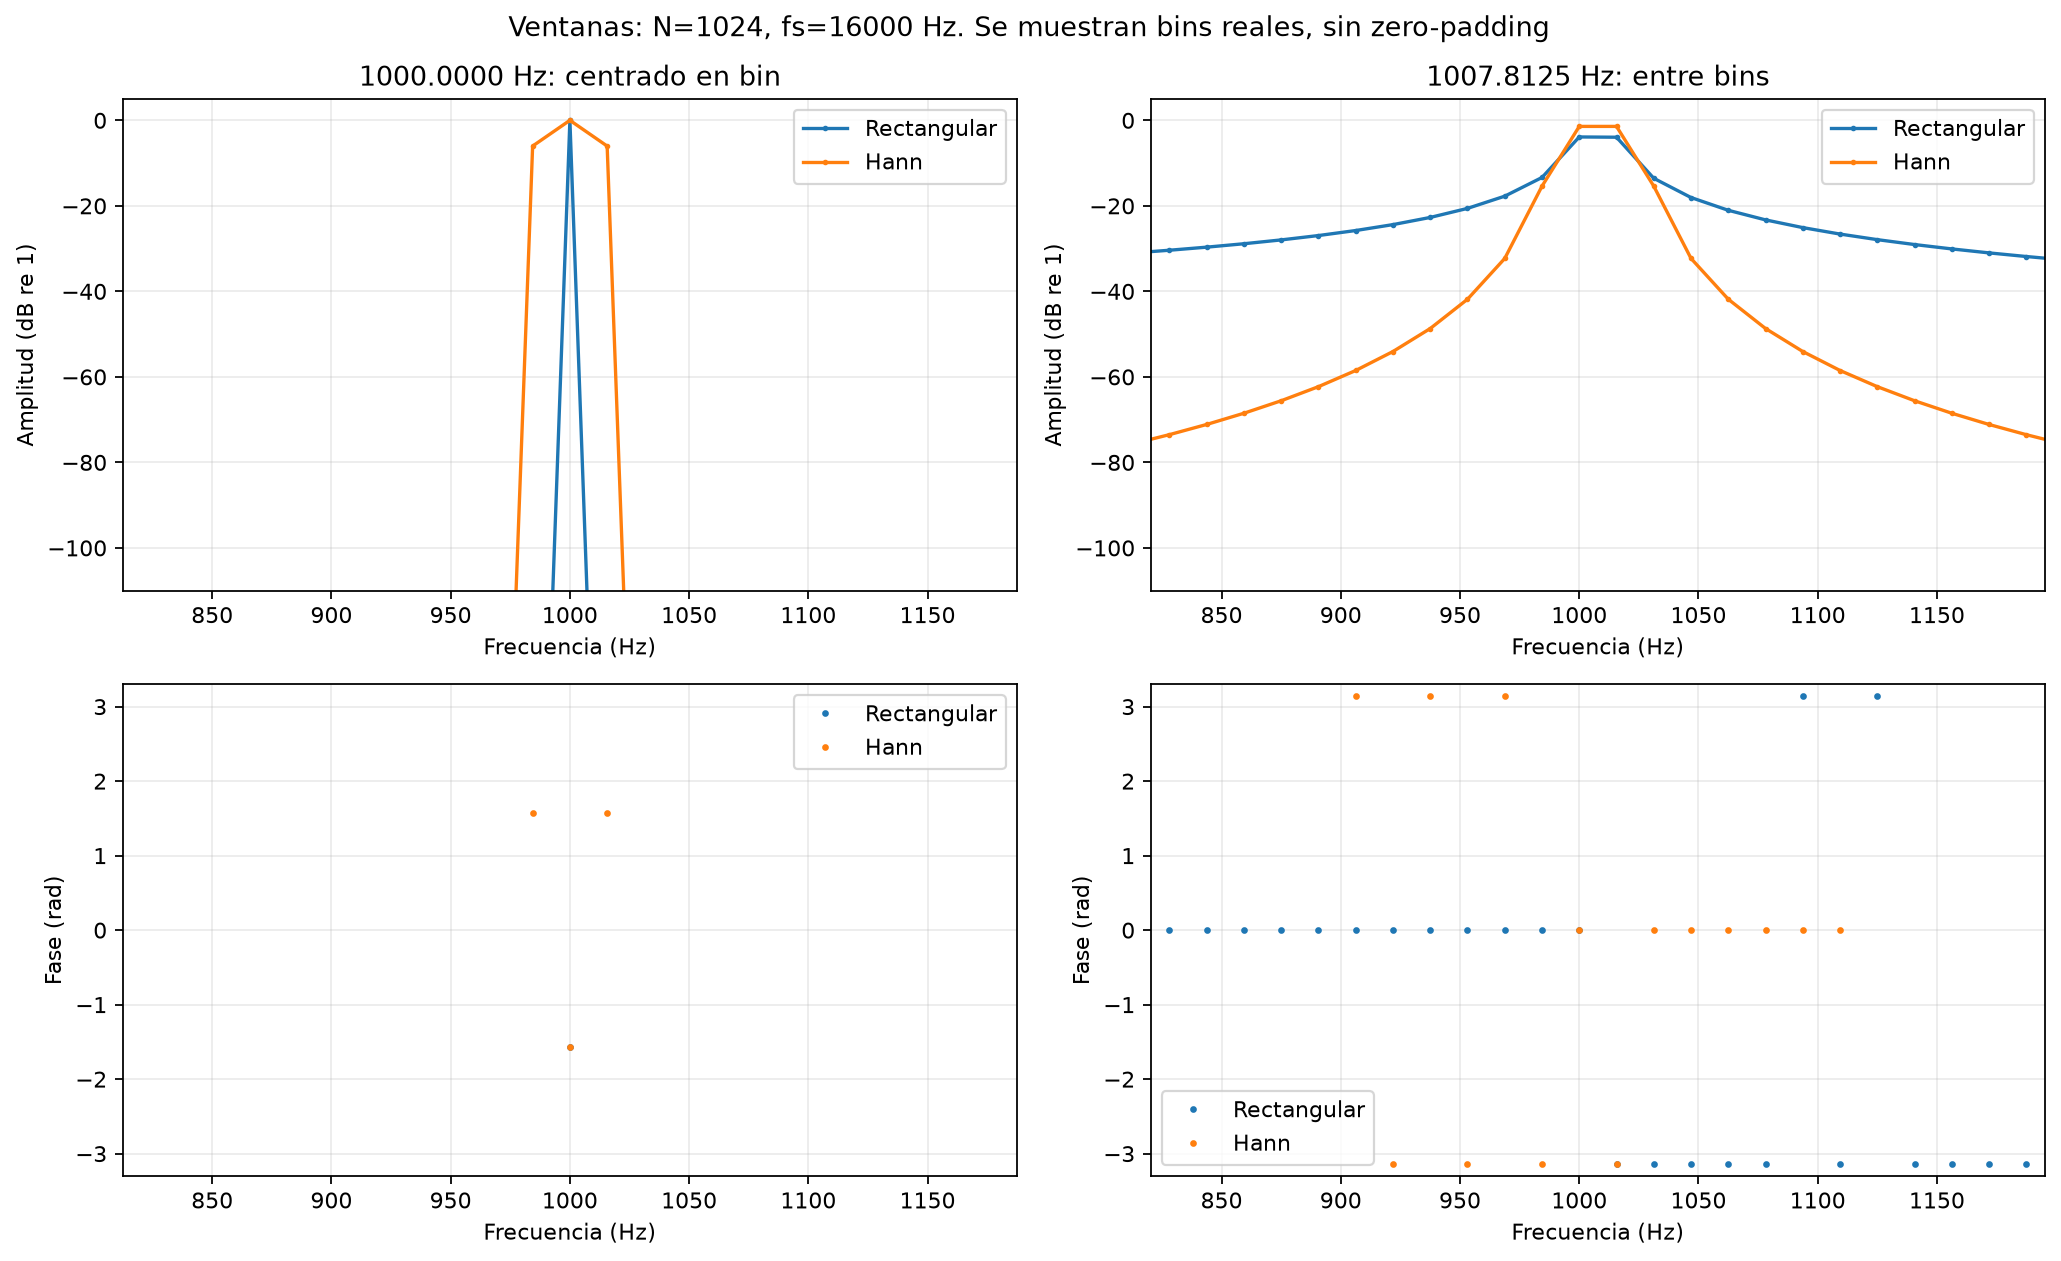

In [4]:
display(Image(filename=str(raiz / "resultados/figuras/fundamentos_ventanas.png")))


### Simetría conjugada

Para una secuencia real: $X[k]=X^*[(-k)\bmod N]$. DC y, para N par, Nyquist deben ser reales. Modificar solo un miembro del par conjugado rompe la condición de reconstrucción real. Tomar después únicamente la parte real de la IFFT oculta el problema, no demuestra que la modificación fue correcta.


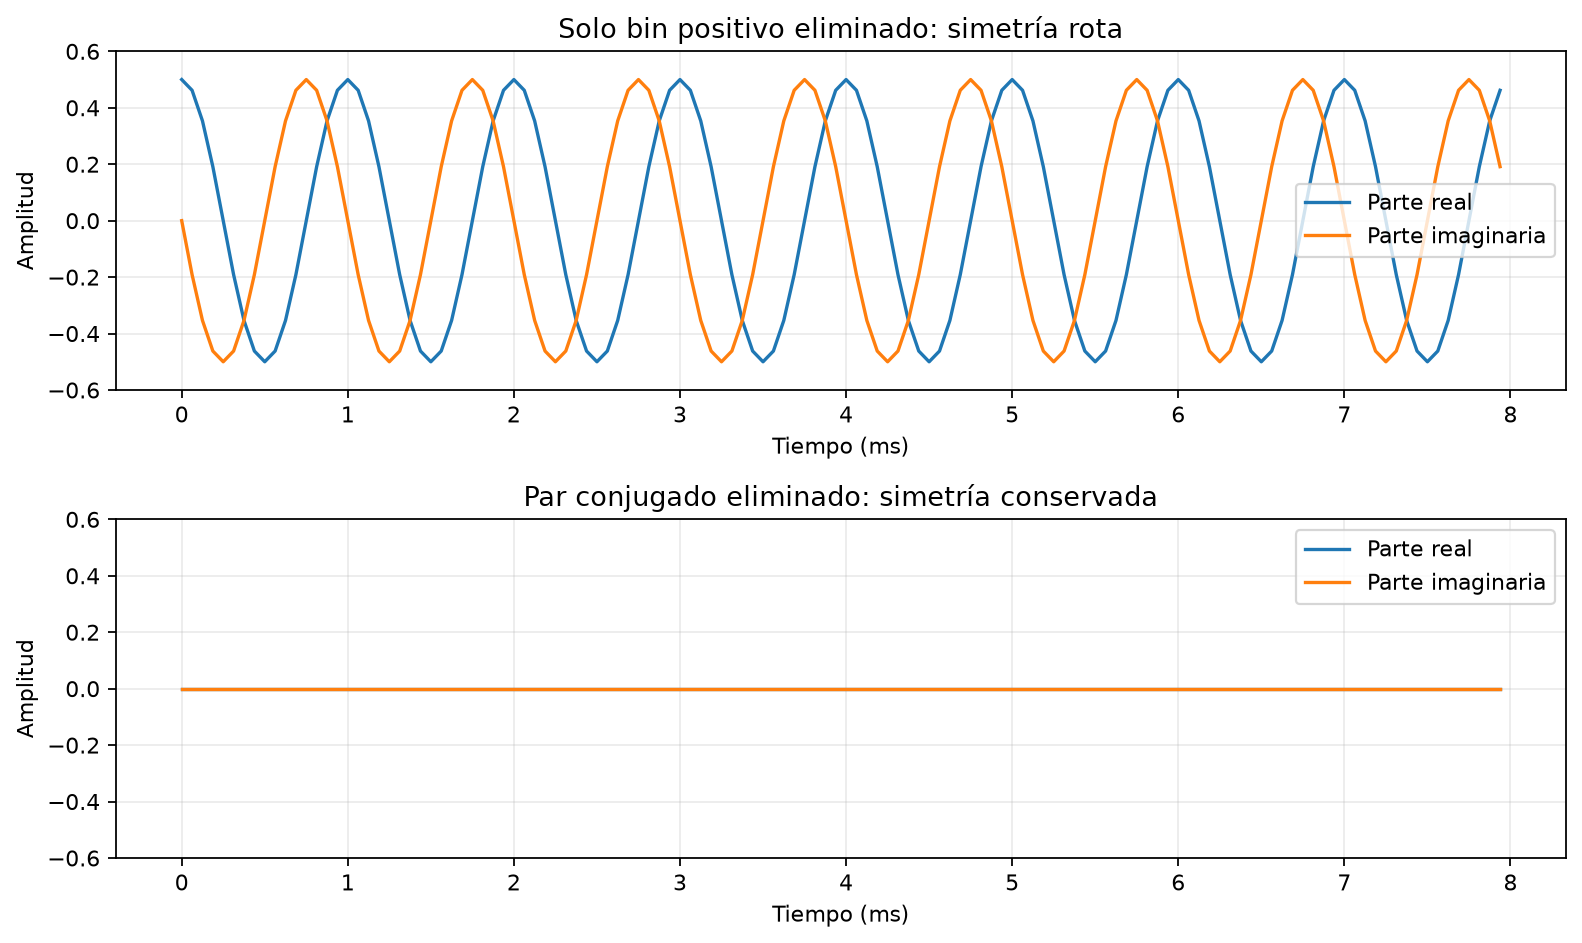

In [5]:
display(Image(filename=str(raiz / "resultados/figuras/fundamentos_simetria.png")))


## 3. Caracterización de los tres casos

Las magnitudes y fases corresponden a un bloque después del fade inicial. Las energías se calculan sobre el registro completo **sin ventana**, usando Parseval y contando una sola vez DC/Nyquist. Las bandas particionan el espectro; sus porcentajes suman 100% por señal. La energía de la mezcla no permite separar automáticamente ruido y señal útil.

La fase representada es el argumento del coeficiente FFT, referido al inicio del bloque: no tiene por qué coincidir directamente con la fase configurada para cada seno.




[{'caso': 'caso_1',
  'semilla': 20261011,
  'fs_hz': 16000,
  'n_bloque': 1024,
  'n_muestras': 96000,
  'snr_objetivo_db': 2.0,
  'snr_obtenida_db': 2.000000000000001,
  'error_simetria_max': 1.4210854715202004e-14},
 {'caso': 'caso_2',
  'semilla': 20261012,
  'fs_hz': 16000,
  'n_bloque': 1024,
  'n_muestras': 96000,
  'snr_objetivo_db': 2.0,
  'snr_obtenida_db': 1.9999999999999984,
  'error_simetria_max': 8.881784197001252e-15},
 {'caso': 'caso_3',
  'semilla': 20261013,
  'fs_hz': 16000,
  'n_bloque': 1024,
  'n_muestras': 96000,
  'snr_objetivo_db': 2.0,
  'snr_obtenida_db': 2.0000000000000004,
  'error_simetria_max': 1.4210854715202004e-14}]

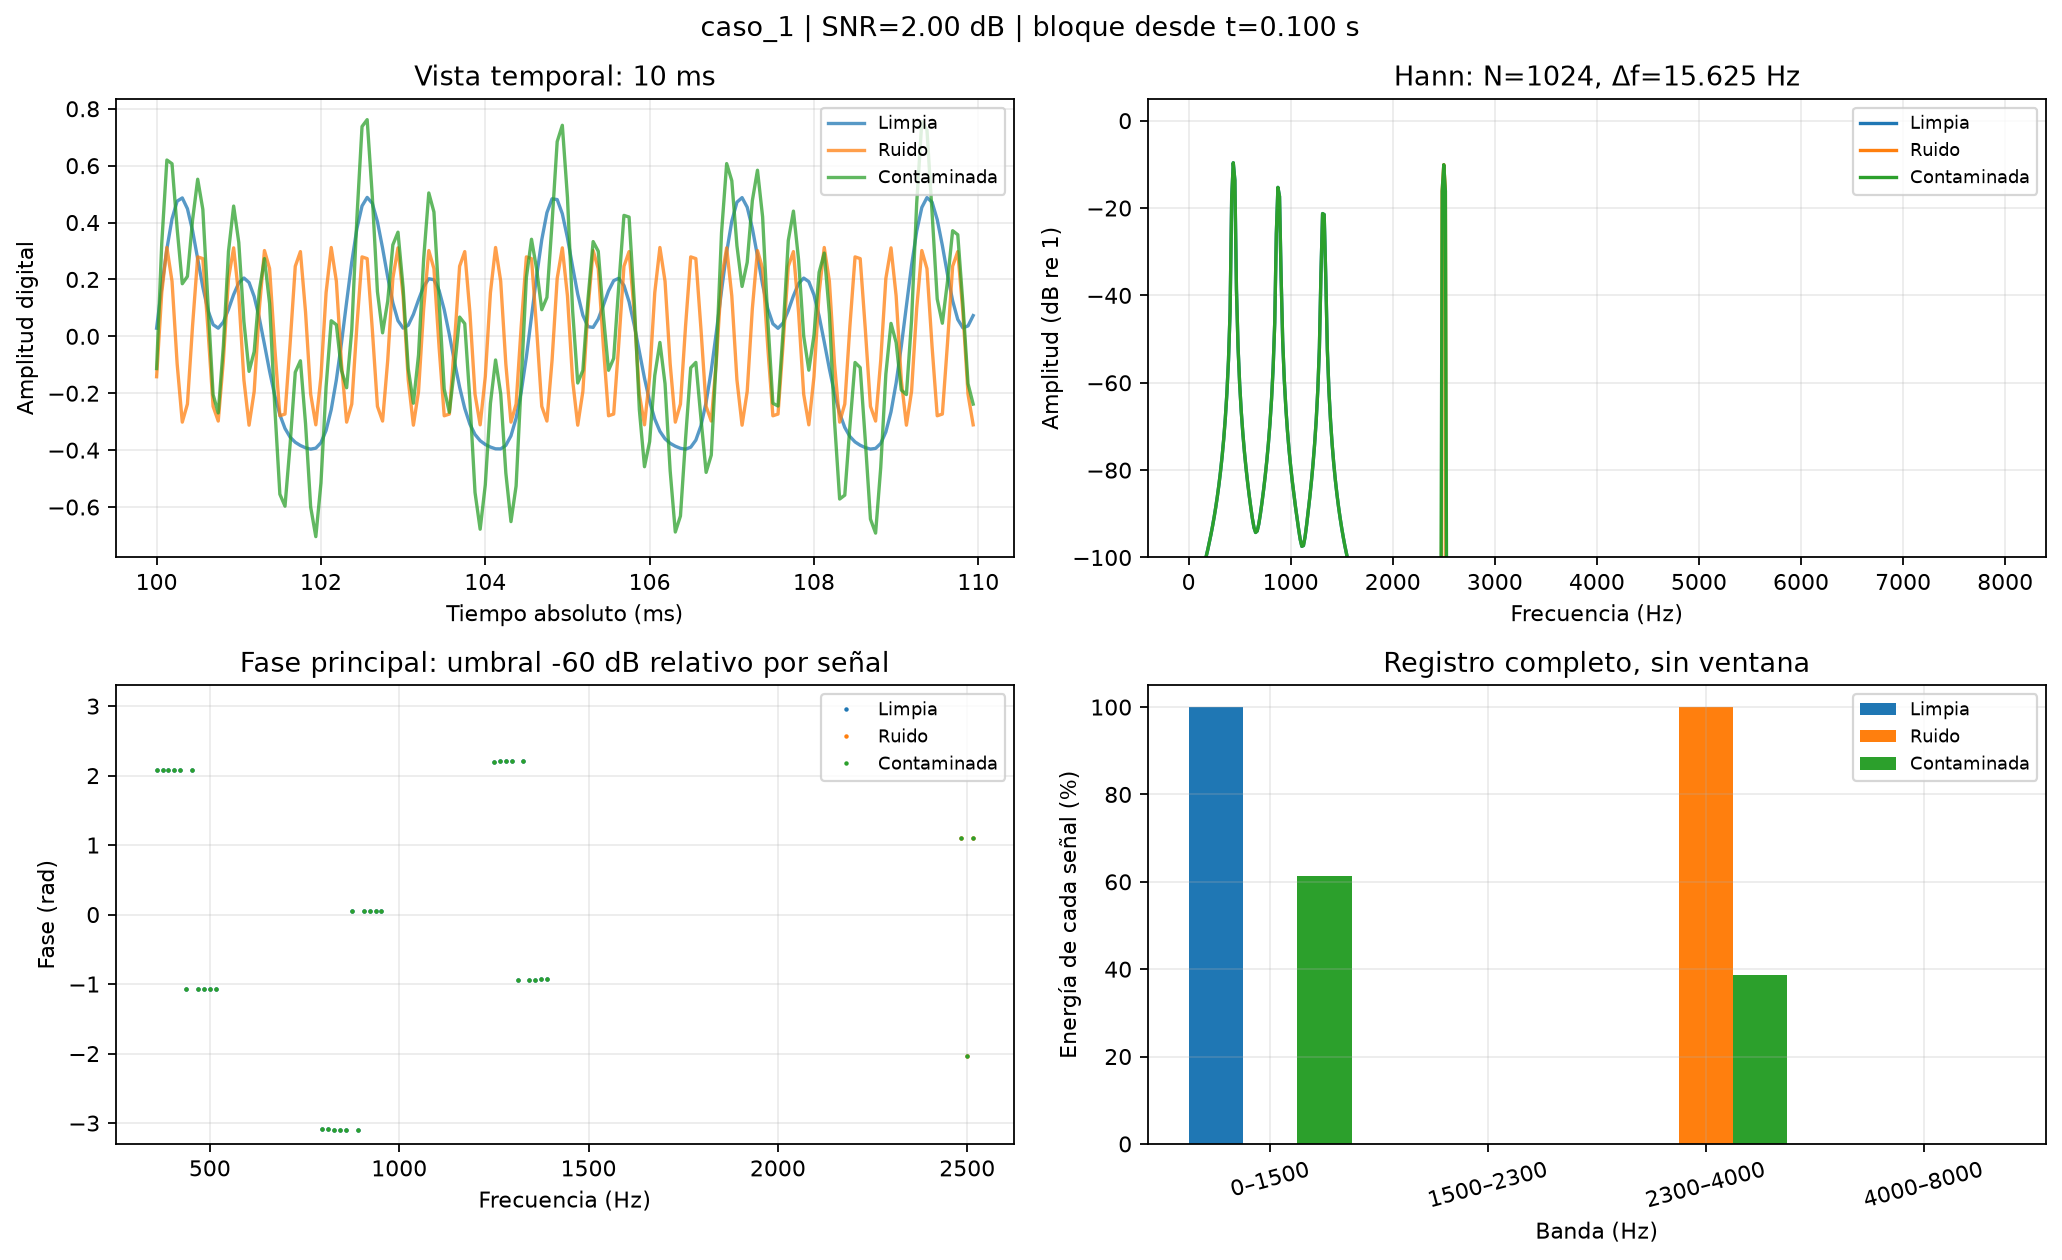

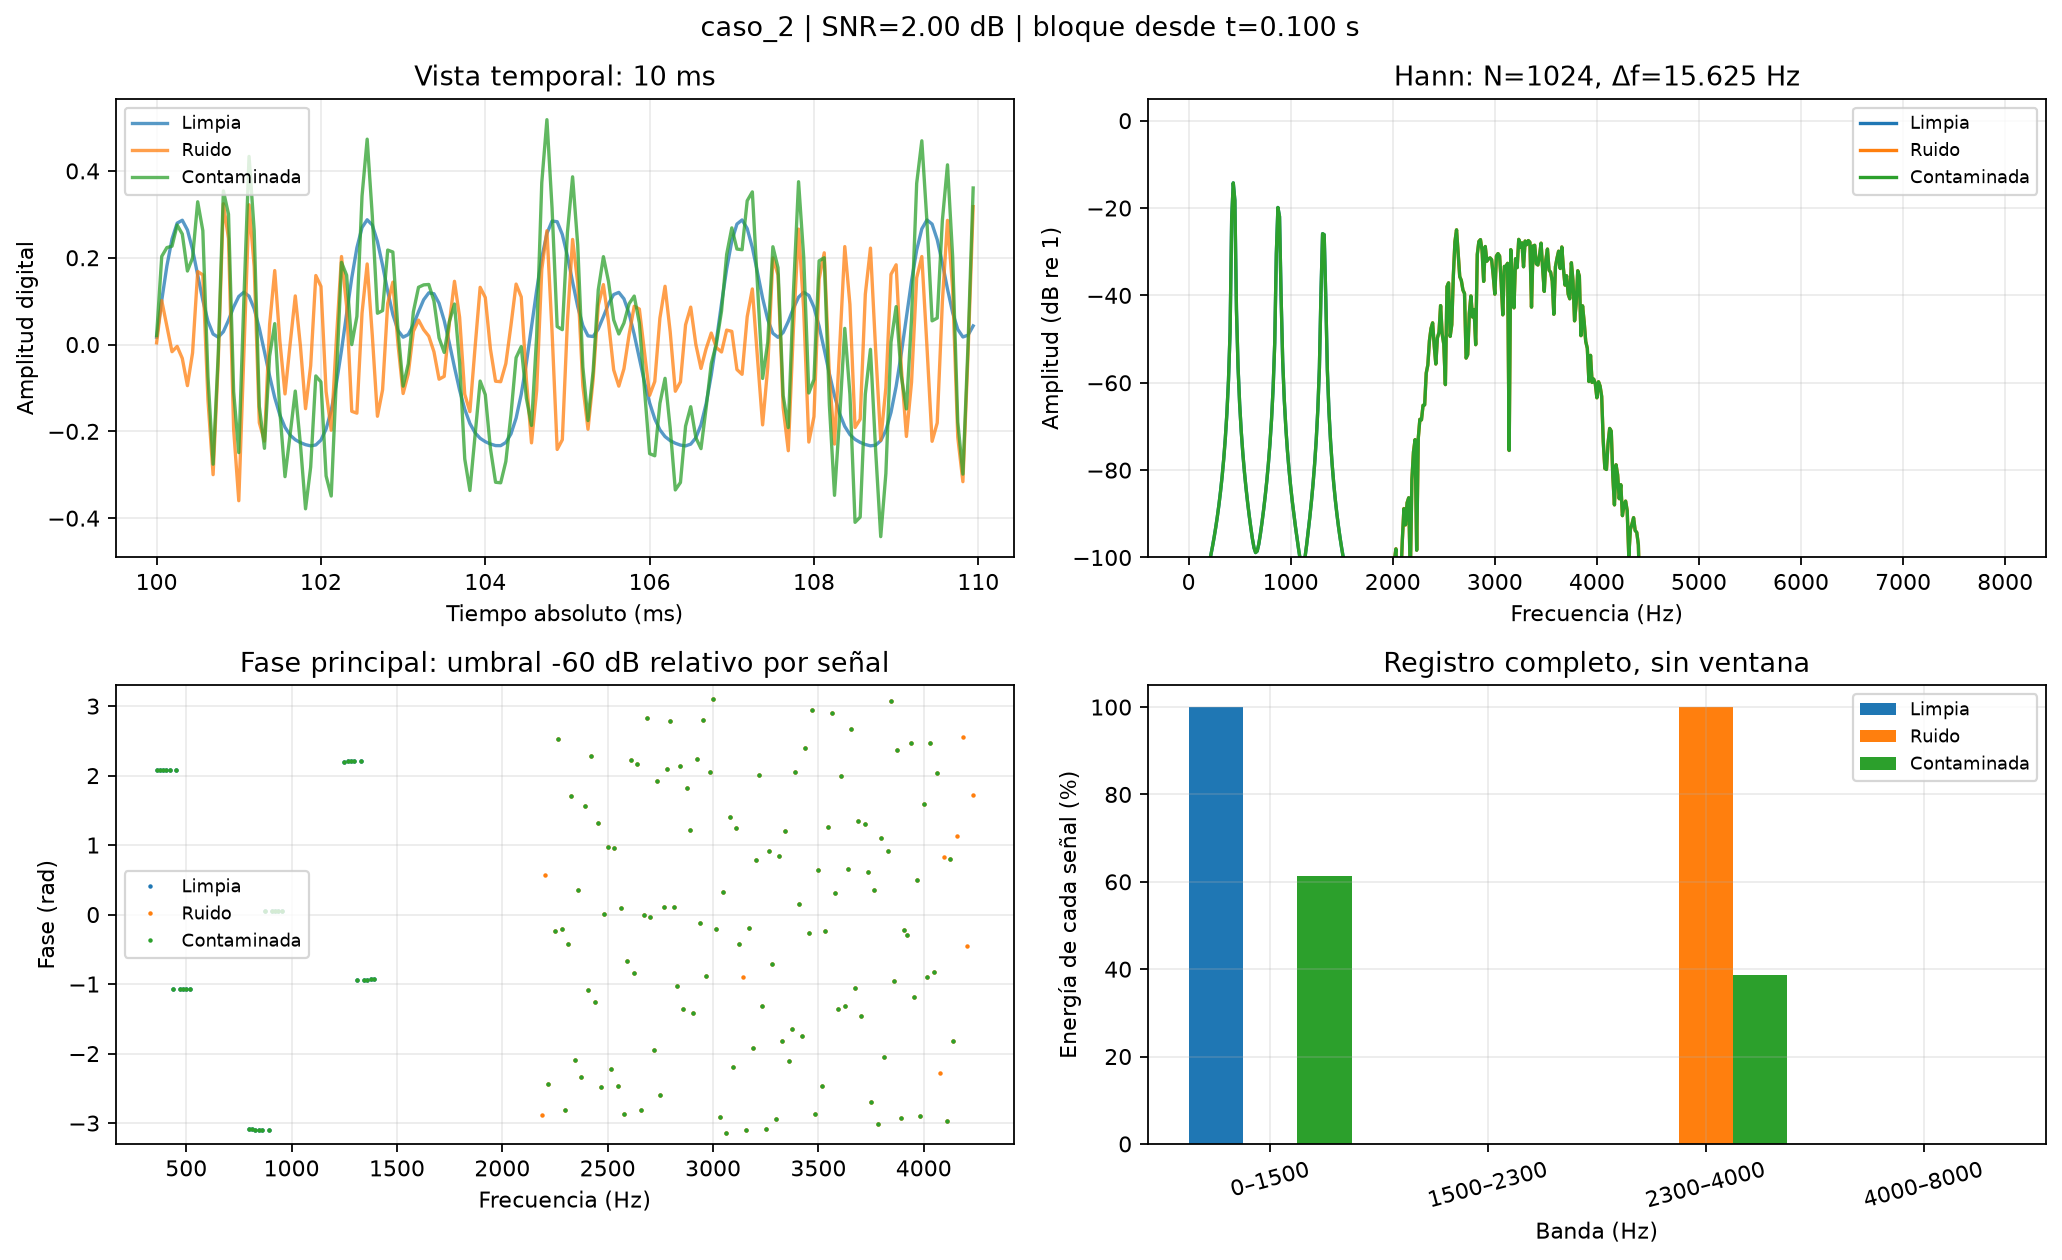

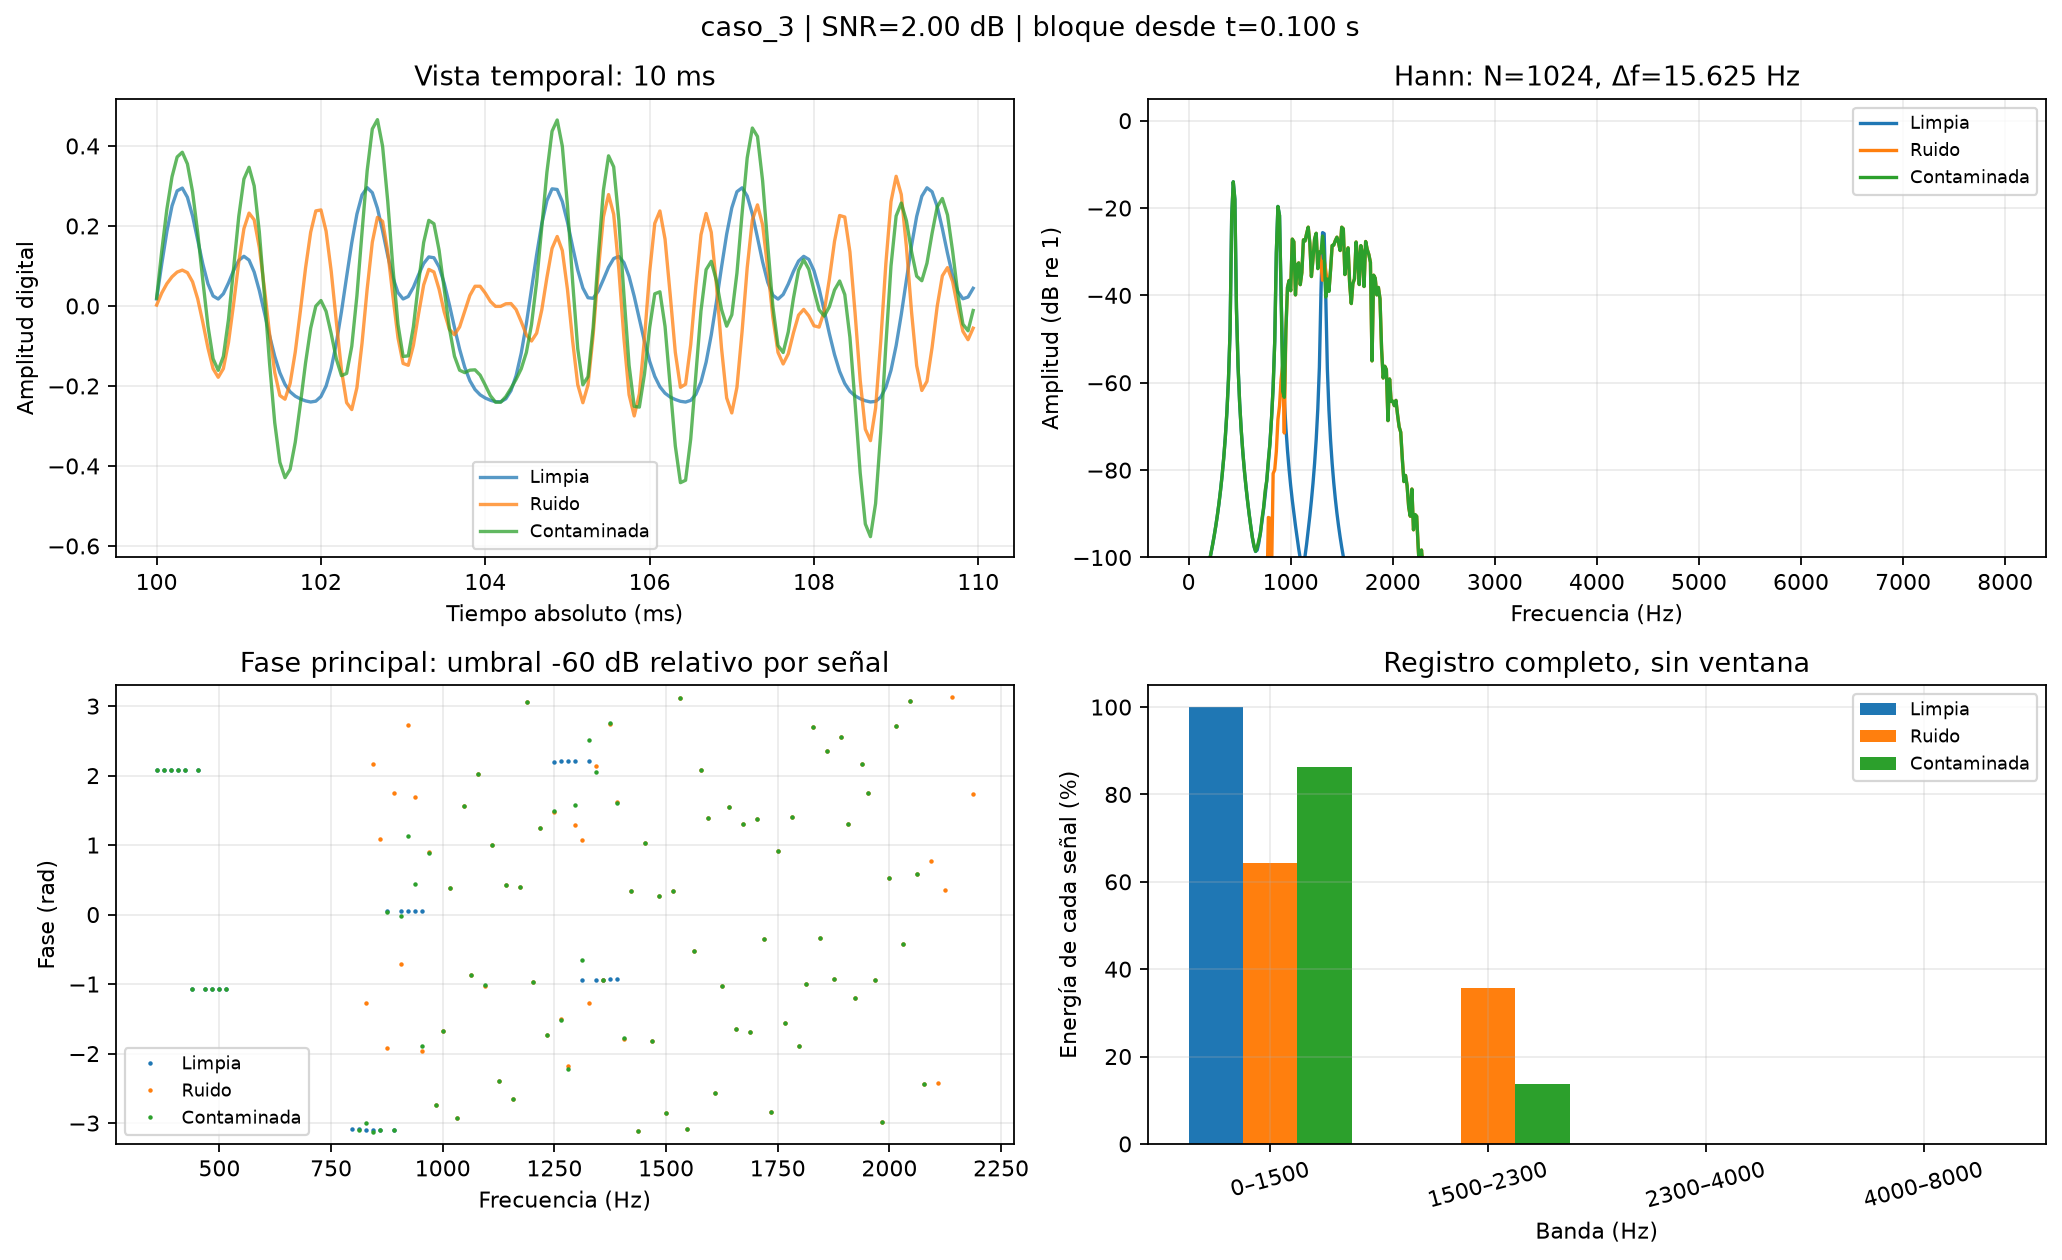

In [6]:
resumen = analizar_todos(casos)
display(resumen)
for nombre in casos:
    display(Image(filename=str(raiz / f"resultados/figuras/{nombre}_caracterizacion.png")))


## 4. Interpretación inicial y límites de identificación

- **Caso 1:** un pico estrecho a 2500 Hz está fuera de las componentes útiles conocidas. La separación permite proponer rechazo espectral o filtrado pasa bajas. Ser un pico grande, por sí solo, no demuestra que sea ruido.
- **Caso 2:** el exceso de energía entre 2500 y 3800 Hz puede identificarse si se conoce previamente la banda útil. La banda del ruido no tiene bordes ideales: el generador usa un Butterworth de orden finito.
- **Caso 3:** ruido y señal comparten frecuencias alrededor de 1320 Hz. Eliminar esa región degrada también una componente útil. Con la mezcla sola y sin información adicional, la descomposición en señal y ruido no es única y no se puede garantizar una recuperación perfecta.

Estas interpretaciones se basan en la configuración conocida de este banco. Los filtros futuros recibirán la señal contaminada; la referencia limpia y el ruido aislado quedan reservados para evaluar sus resultados.




## 5. Diseño y validación del filtro temporal FIR

Se diseñó un filtro pasa bajas para conservar las componentes útiles de
440, 880 y 1320 Hz y reducir el ruido separado de los casos 1 y 2.

Especificaciones:
- Frecuencia de muestreo: 16000 Hz.
- Banda de paso: 0–1500 Hz.
- Banda de transición: 1500–2300 Hz.
- Banda de rechazo: 2300–8000 Hz.
- Rizado máximo: 0.1 dB.
- Atenuación mínima de rechazo: 60 dB.

El diseño mediante ventana Kaiser produce 81 coeficientes, correspondientes
a un filtro de orden 80. Su ecuación de diferencias es:

$$y[n]=\sum_{k=0}^{80}b_kx[n-k].$$

La función de transferencia es:

$$H(z)=\sum_{k=0}^{80}b_kz^{-k}
=\frac{b_0z^{80}+b_1z^{79}+\cdots+b_{80}}{z^{80}}.$$

Los polos están en el origen y la región de convergencia causal es
$|z|>0$. El sistema es BIBO estable porque su respuesta impulsional tiene
longitud finita y es absolutamente sumable.

Los coeficientes simétricos producen fase lineal y un retardo de grupo
de 40 muestras, equivalente a 2.5 ms.

La implementación propia conserva el estado entre bloques y se compara
contra `scipy.signal.lfilter` con iguales condiciones iniciales.
Los coeficientes completos y las verificaciones se exportan a archivos.
La cuantización de coeficientes no constituye todavía una simulación
completa de aritmética fija.

Fuentes: apuntes S7L2 del curso para fase y retardo de grupo;
documentación oficial de SciPy para `kaiserord` y `firwin`.

FIR: orden 80, 81 coeficientes, retardo 40 muestras (2.50 ms)
Rizado 0.009692 dB; rechazo mínimo 64.712 dB
caso_1: error vs lfilter=1.665e-16; mejora SNR alineada=69.898 dB
caso_2: error vs lfilter=1.110e-16; mejora SNR alineada=73.211 dB
caso_3: error vs lfilter=2.220e-16; mejora SNR alineada=0.196 dB
Orden: 80
Número de coeficientes: 81
Retardo (muestras): 40
Retardo (ms): 2.5
Rizado medido (dB): 0.009692236202846698
Rechazo mínimo medido (dB): 64.7119491721538


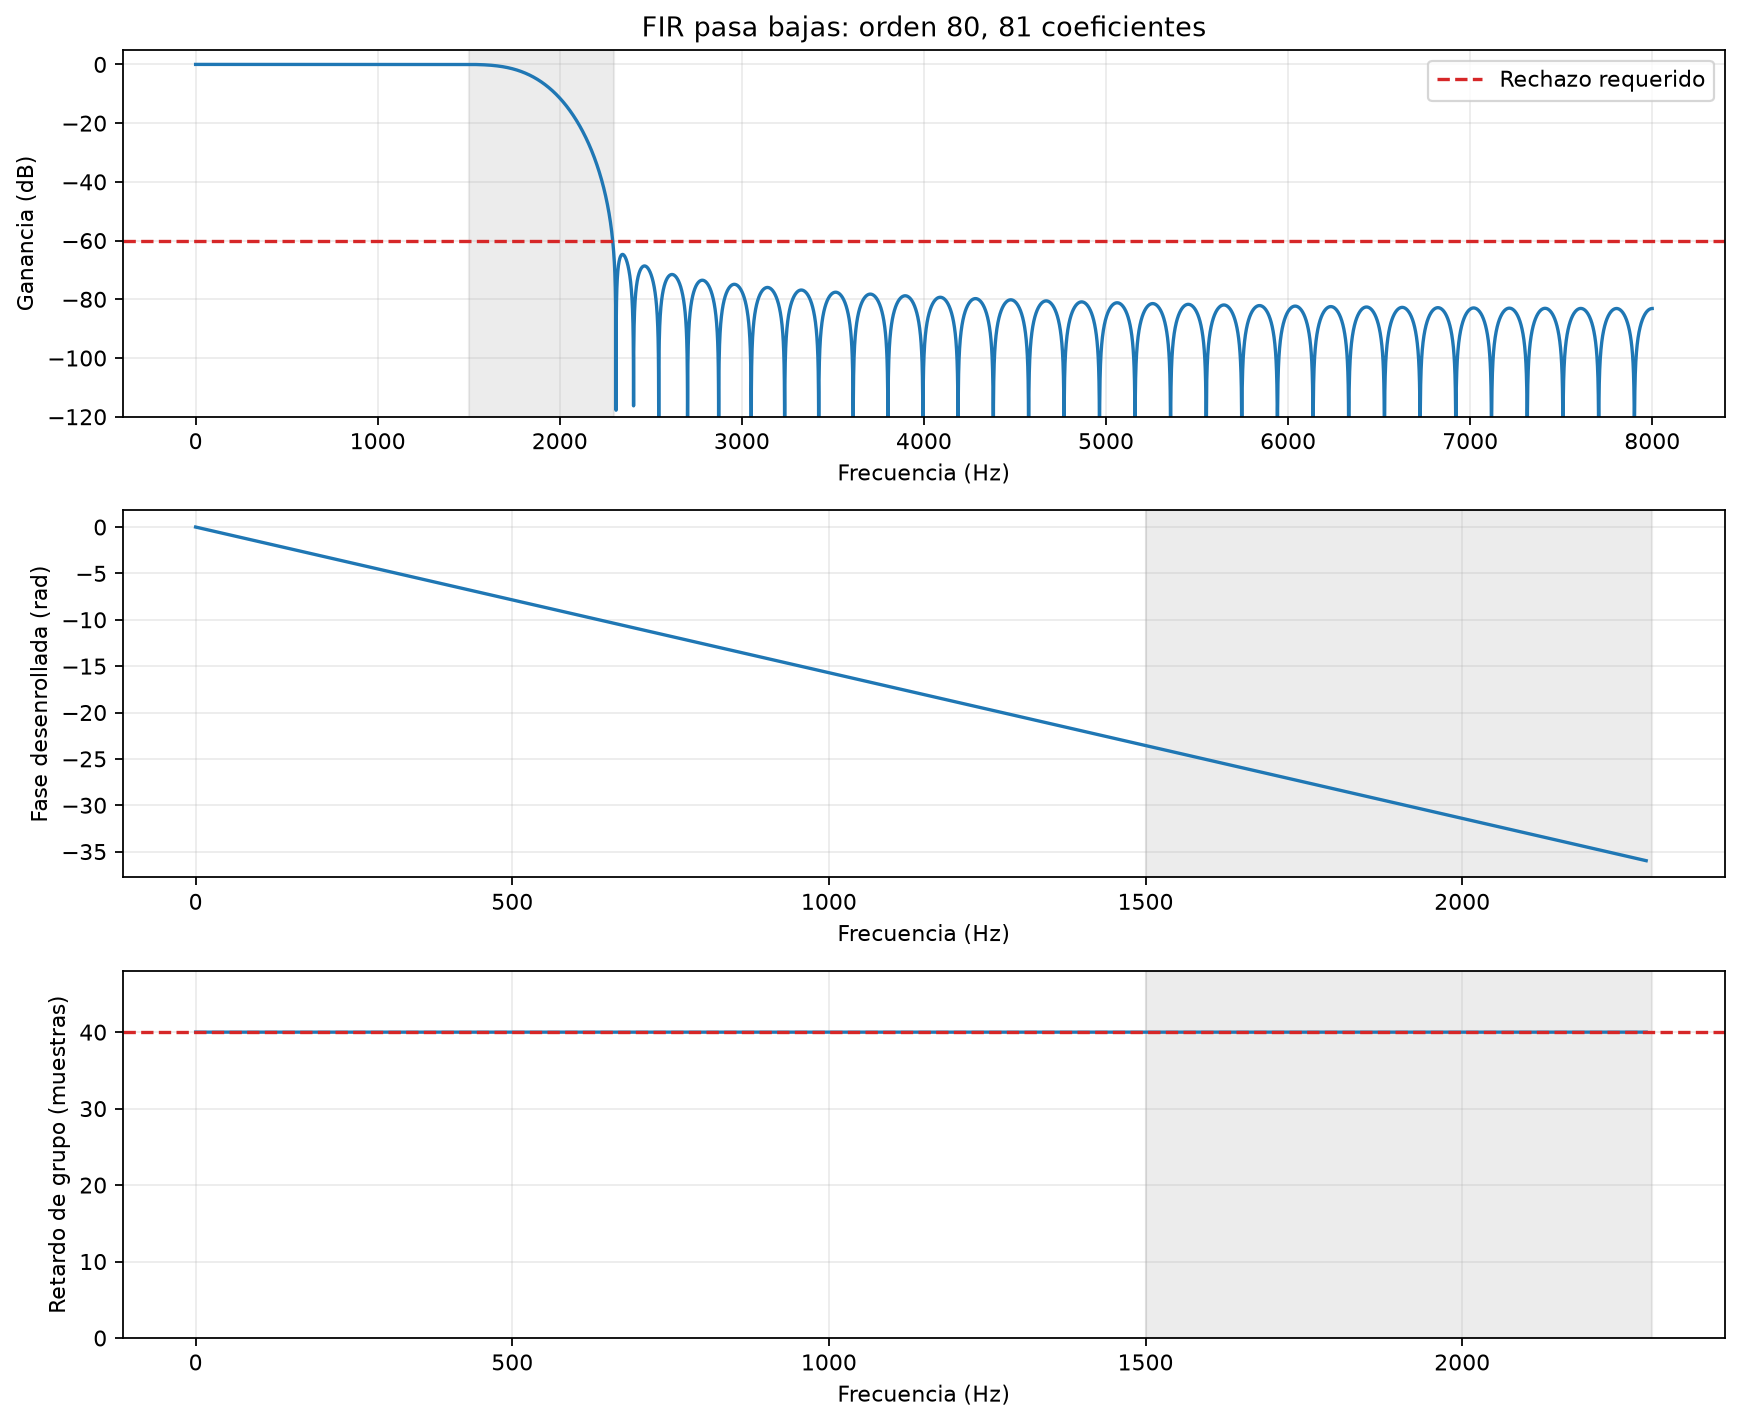

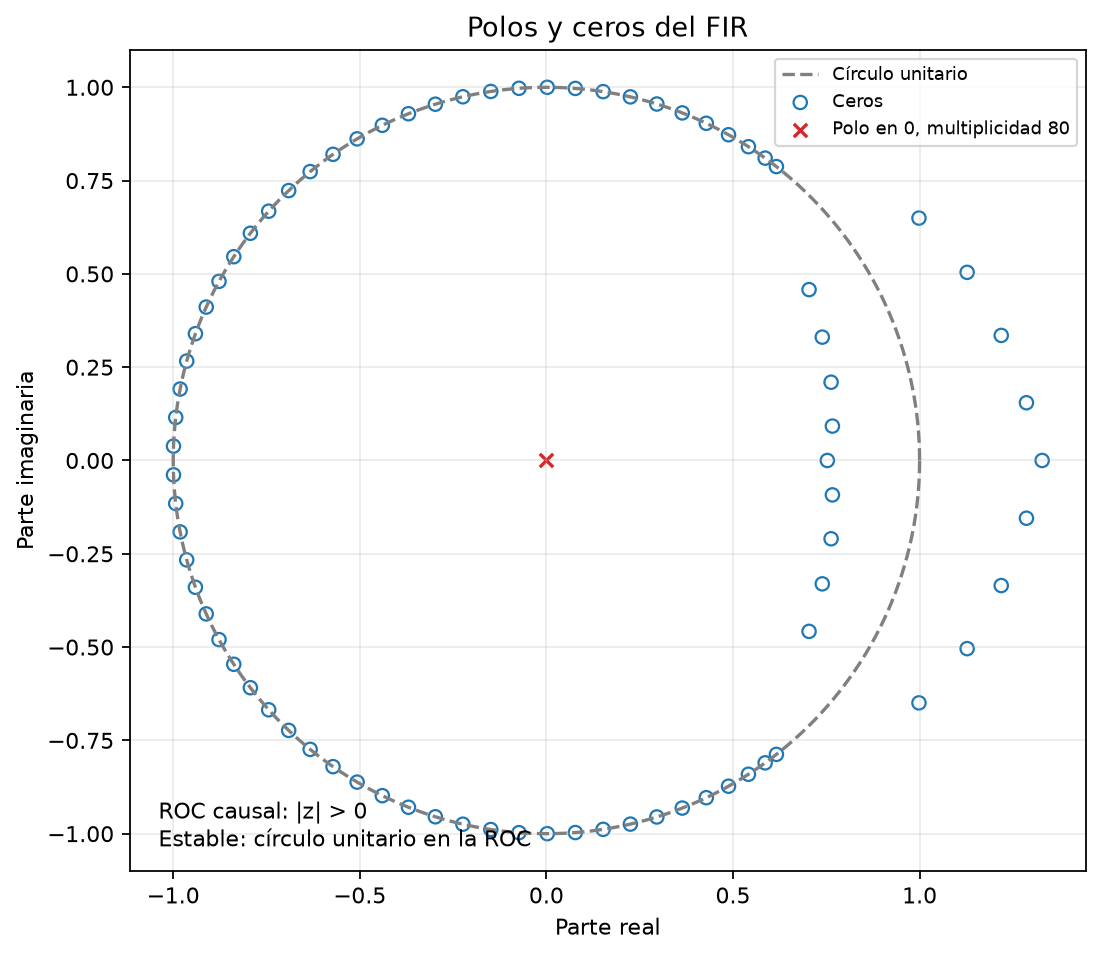

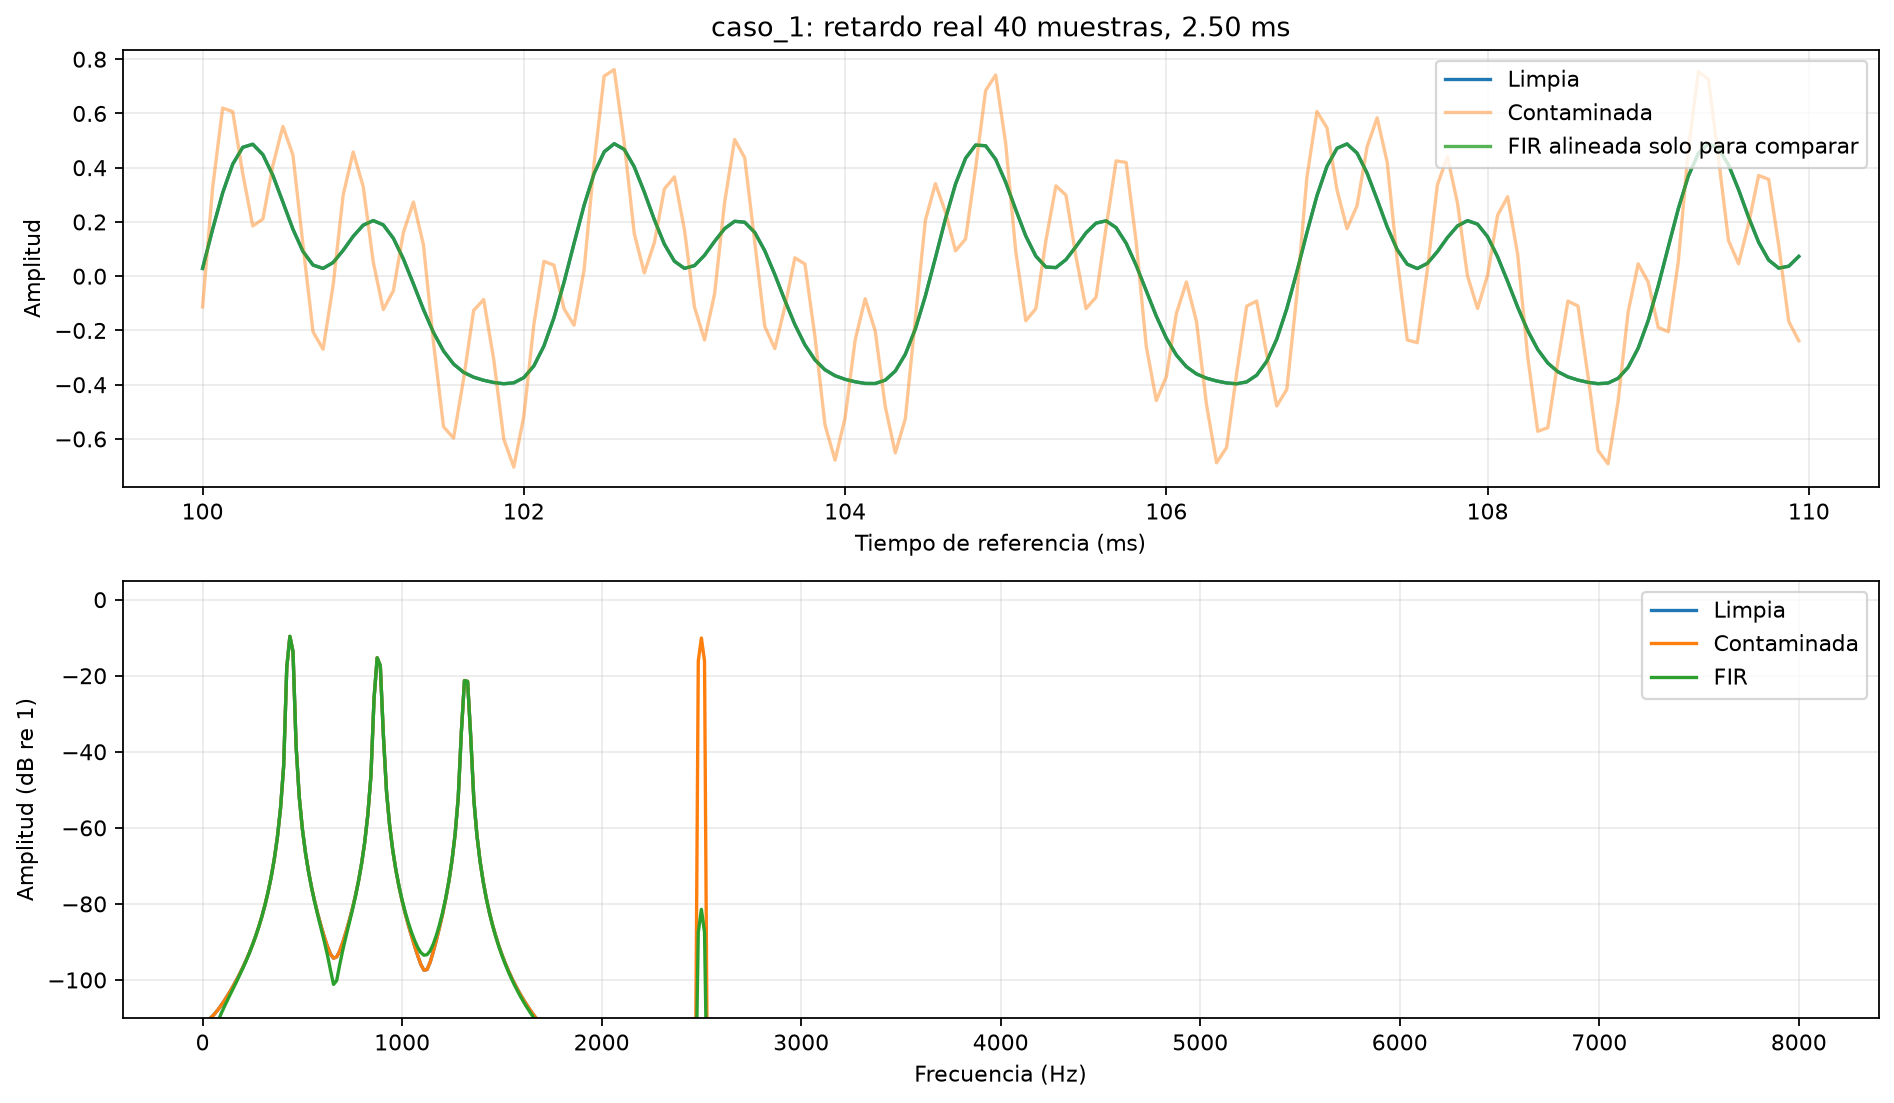

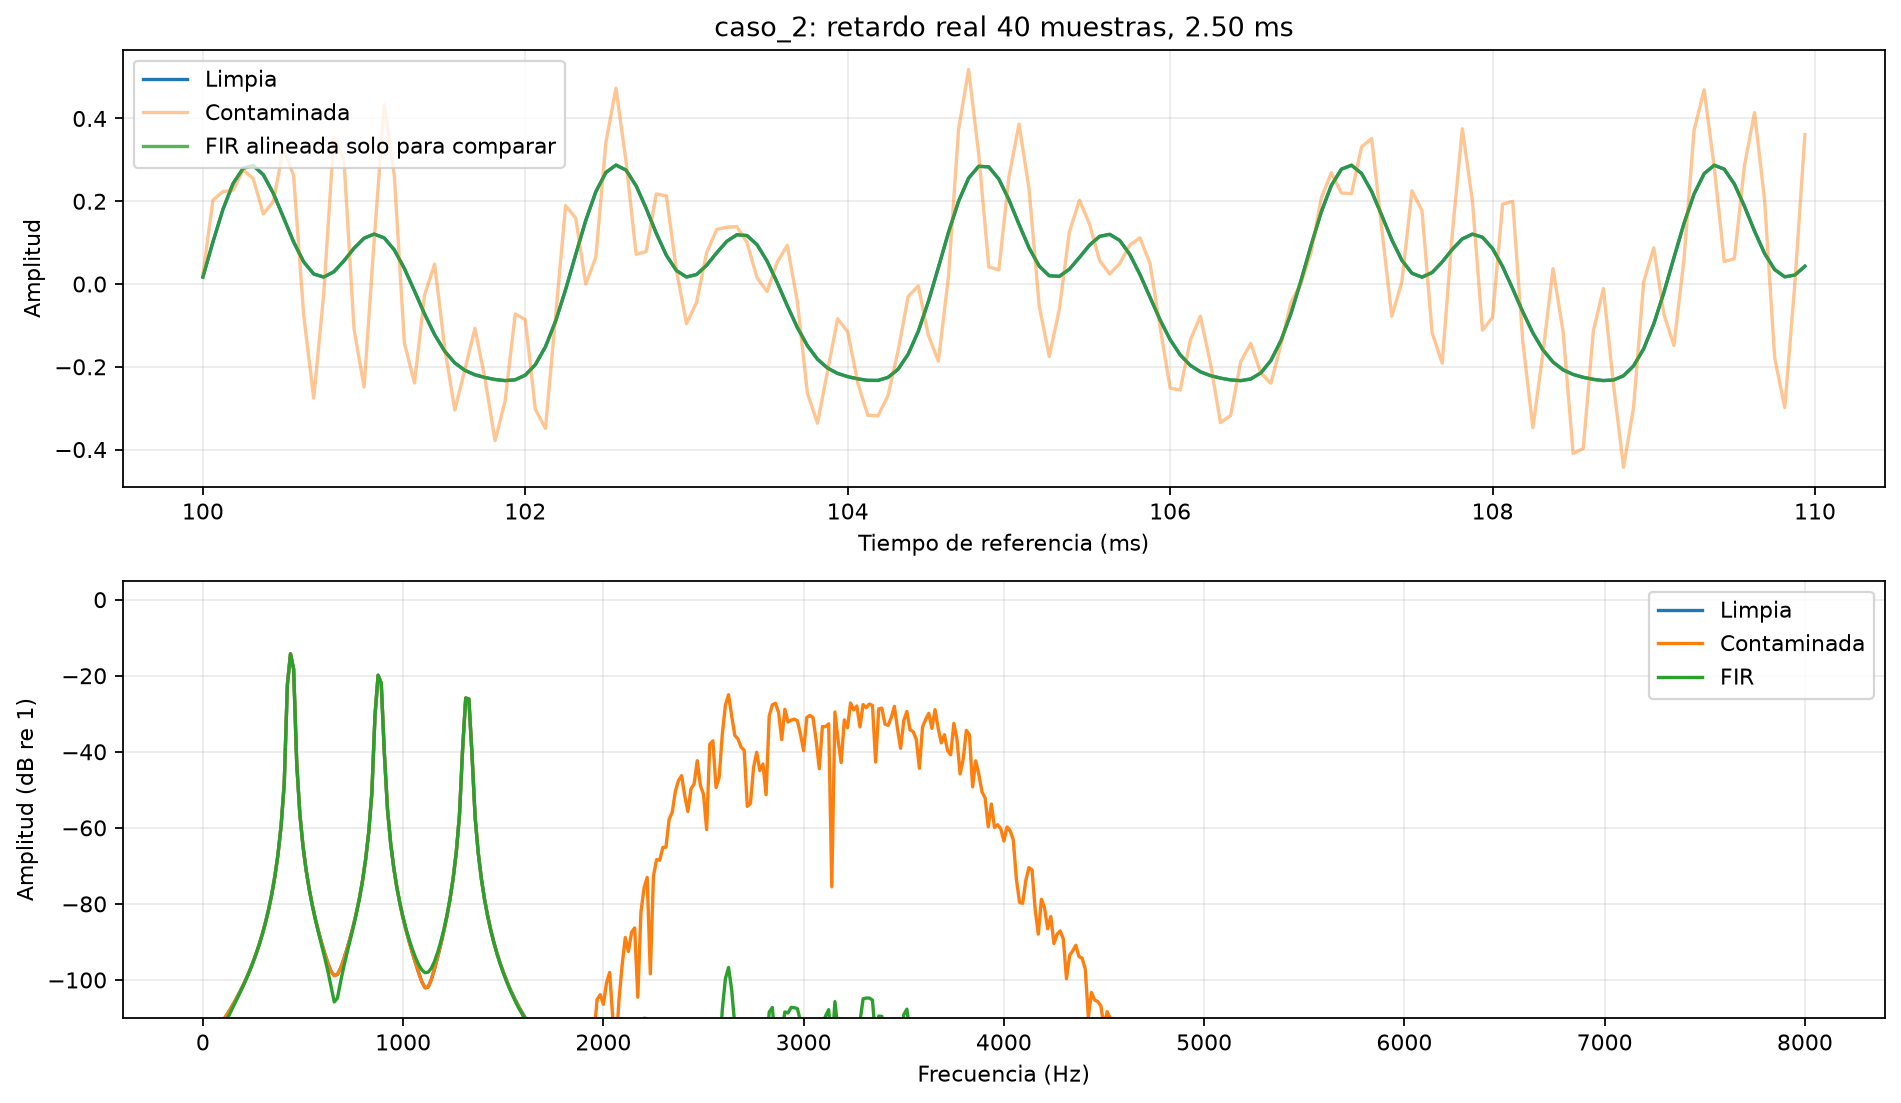

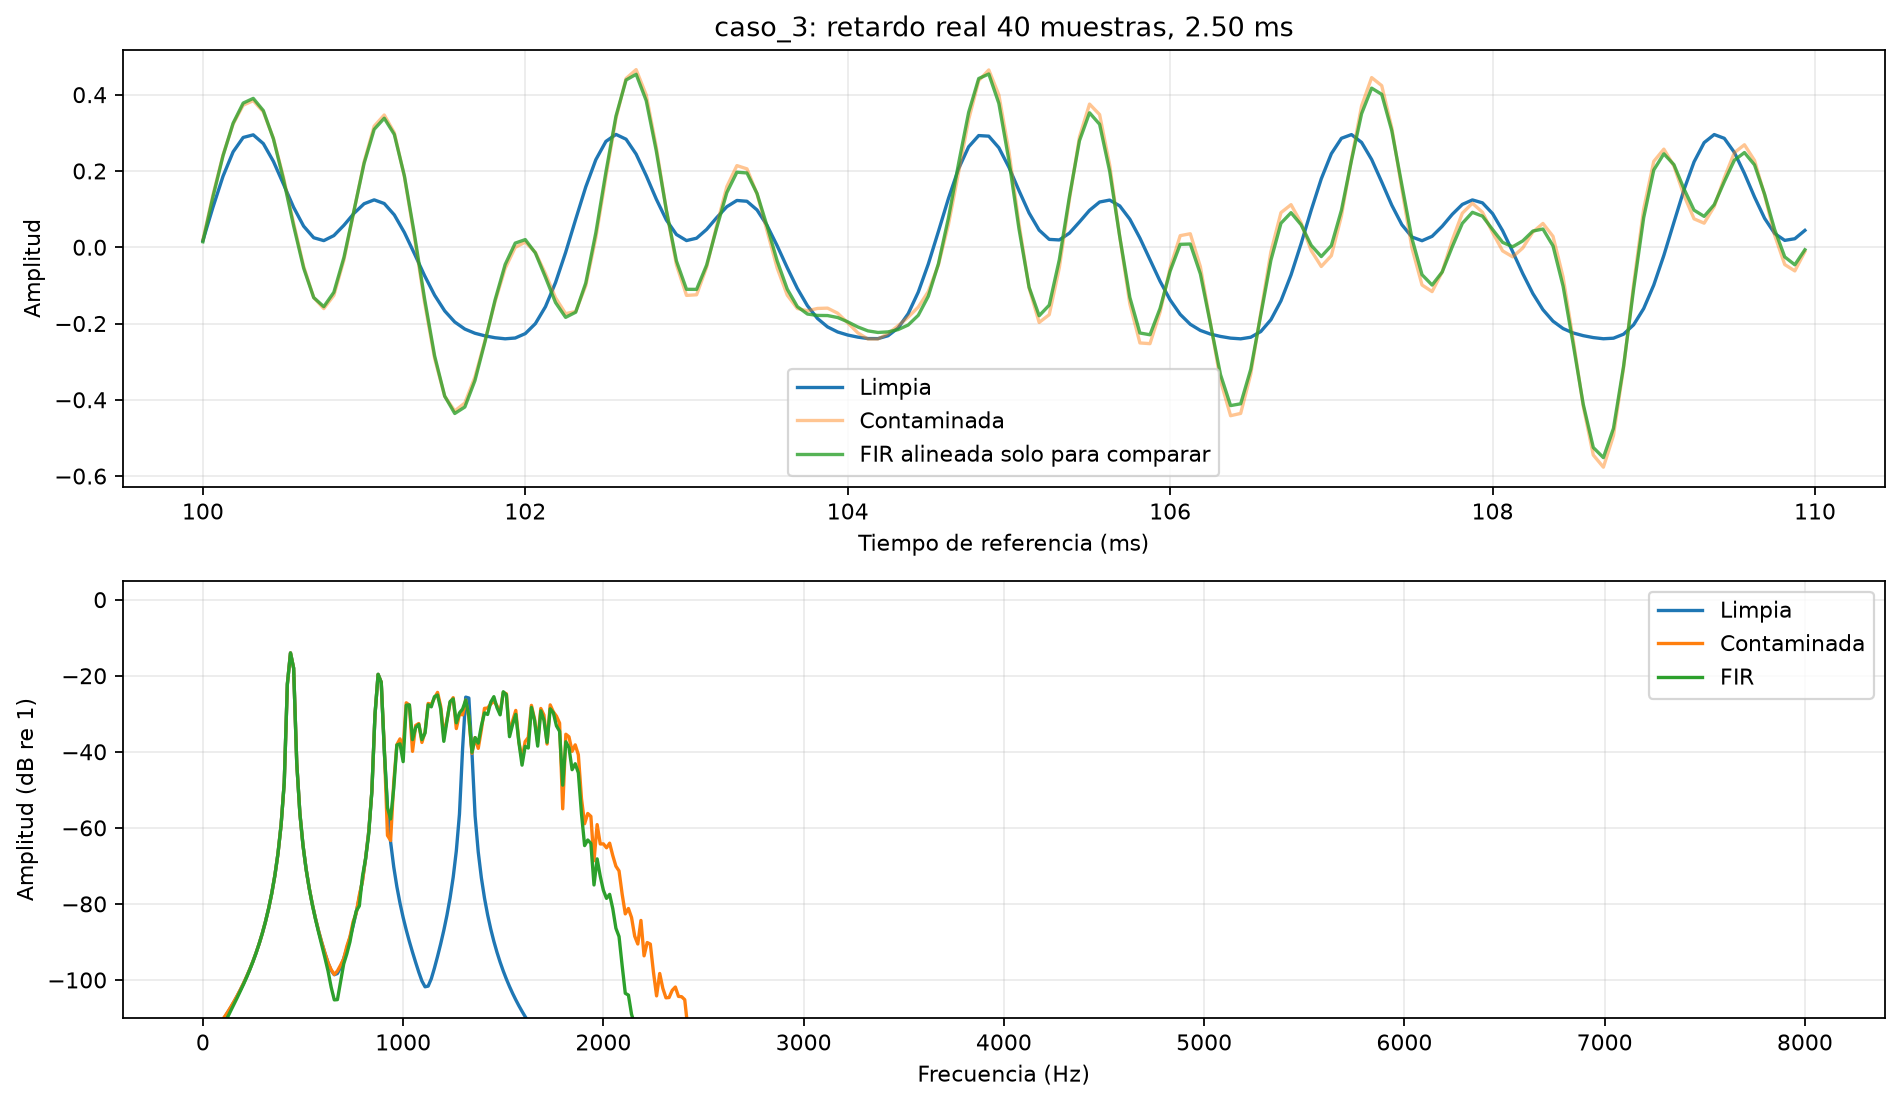

In [7]:
from src.filtros_temporales import ejecutar_temporal

temporal = ejecutar_temporal(casos)

print("Orden:", temporal["diseno"]["orden"])
print("Número de coeficientes:", temporal["diseno"]["num_coeficientes"])
print("Retardo (muestras):", temporal["diseno"]["retardo_muestras"])
print("Retardo (ms):", temporal["diseno"]["retardo_ms"])
print(
    "Rizado medido (dB):",
    temporal["diseno"]["rizado_pico_a_pico_db"],
)
print(
    "Rechazo mínimo medido (dB):",
    temporal["diseno"]["atenuacion_rechazo_min_db"],
)

for nombre in [
    "fir_respuesta.png",
    "fir_polos_ceros.png",
    "caso_1_fir.png",
    "caso_2_fir.png",
    "caso_3_fir.png",
]:
    display(Image(filename=str(raiz / "resultados" / "figuras" / nombre)))

## 6. Reducción espectral adaptativa mediante FFT/IFFT

La entrada se divide en marcos de 1024 muestras con un salto de 512 muestras.
Se utiliza Hann periódica para análisis y síntesis.

La cadena de procesamiento es:

Marco → ventana → FFT → estimación del ruido → modificación espectral
→ IFFT → reconstrucción mediante solapamiento y normalización.

La estimación utiliza una mediana local de potencia y un suavizado entre
marcos. El parámetro alpha controla la intensidad de reducción.

El algoritmo recibe únicamente la señal contaminada y conoce la banda útil
nominal. La referencia limpia y el ruido aislado se reservan para evaluación.

Las ganancias aplicadas al espectro son reales y no negativas. Se conserva
la simetría conjugada necesaria para reconstruir una señal real mediante
`rfft` e `irfft`.

La reconstrucción utiliza la suma de cuadrados de las ventanas como
denominador. Antes de evaluar la reducción se verifica que la cadena con
ganancia unitaria reconstruya la entrada, incluidos sus extremos.

En el caso de superposición se prueban alpha = 0.5, 1.5, 4 y 12.
Se mide tanto la atenuación del ruido como la distorsión del componente útil:
una reducción más agresiva puede eliminar información de la señal.

La salida offline está alineada con la referencia. Esto no implica
latencia física nula en el futuro sistema embebido.

Fuentes: apuntes S6L2 y S7L1 del curso para transformadas y simetría;
documentación oficial de NumPy y SciPy para las APIs y reconstrucción NOLA.

caso_1: error identidad=4.441e-16; mejora SNR=59.343 dB; energía útil=100.00%
caso_2: error identidad=2.776e-16; mejora SNR=63.729 dB; energía útil=100.00%
caso_3: error identidad=3.331e-16; mejora SNR=4.497 dB; energía útil=96.42%
Experimento de compromiso:
alpha=0.5: ruido atenuado 1.76 dB; energía útil 98.41%; distorsión útil MSE=9.03298e-05
alpha=1.5: ruido atenuado 4.79 dB; energía útil 96.42%; distorsión útil MSE=0.000385079
alpha=4: ruido atenuado 11.49 dB; energía útil 94.20%; distorsión útil MSE=0.00109897
alpha=12: ruido atenuado 24.85 dB; energía útil 93.14%; distorsión útil MSE=0.00167669
Resultados espectrales:
caso_1: mejora SNR = 59.343 dB; energía útil = 100.00%
caso_2: mejora SNR = 63.729 dB; energía útil = 100.00%
caso_3: mejora SNR = 4.497 dB; energía útil = 96.42%

Experimento de reducción agresiva:
alpha = 0.5: atenuación ruido = 1.76 dB; distorsión útil MSE = 9.03298e-05
alpha = 1.5: atenuación ruido = 4.79 dB; distorsión útil MSE = 0.000385079
alpha = 4: atenuaci

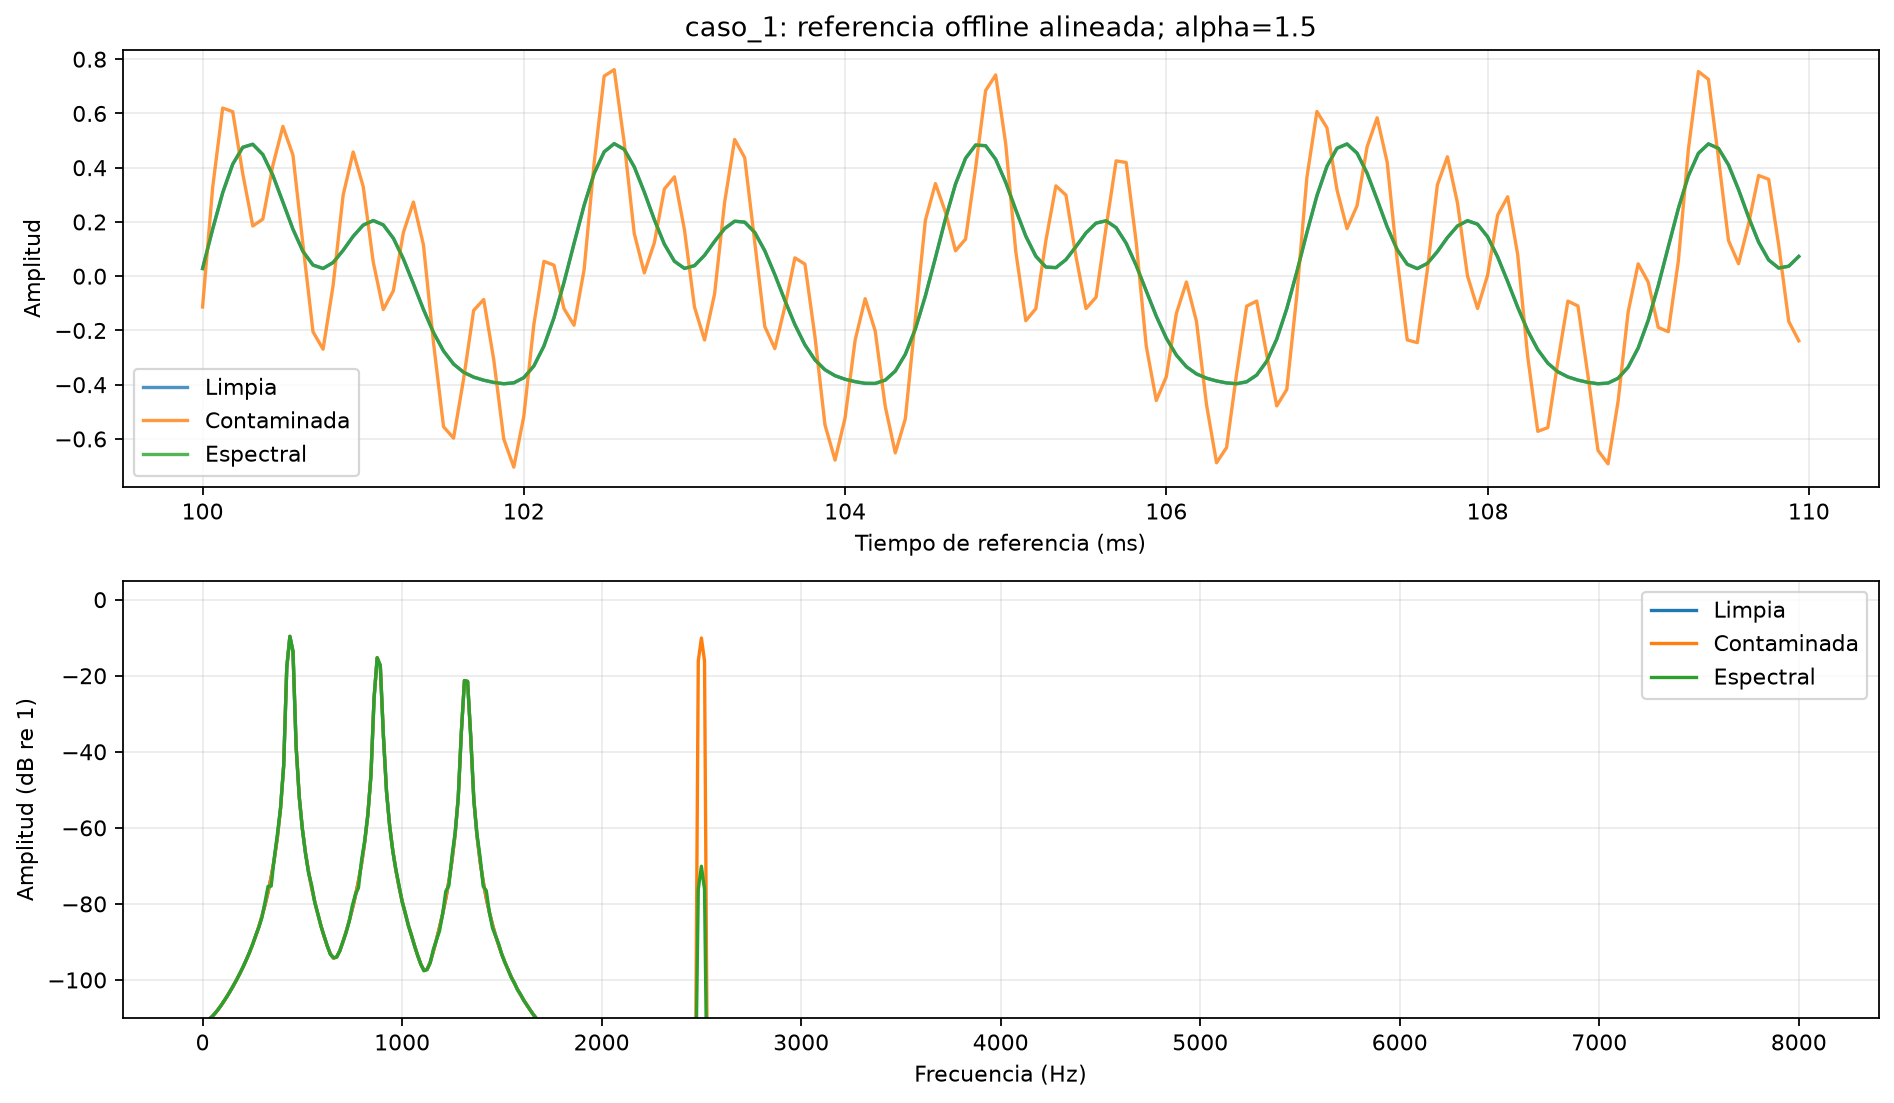

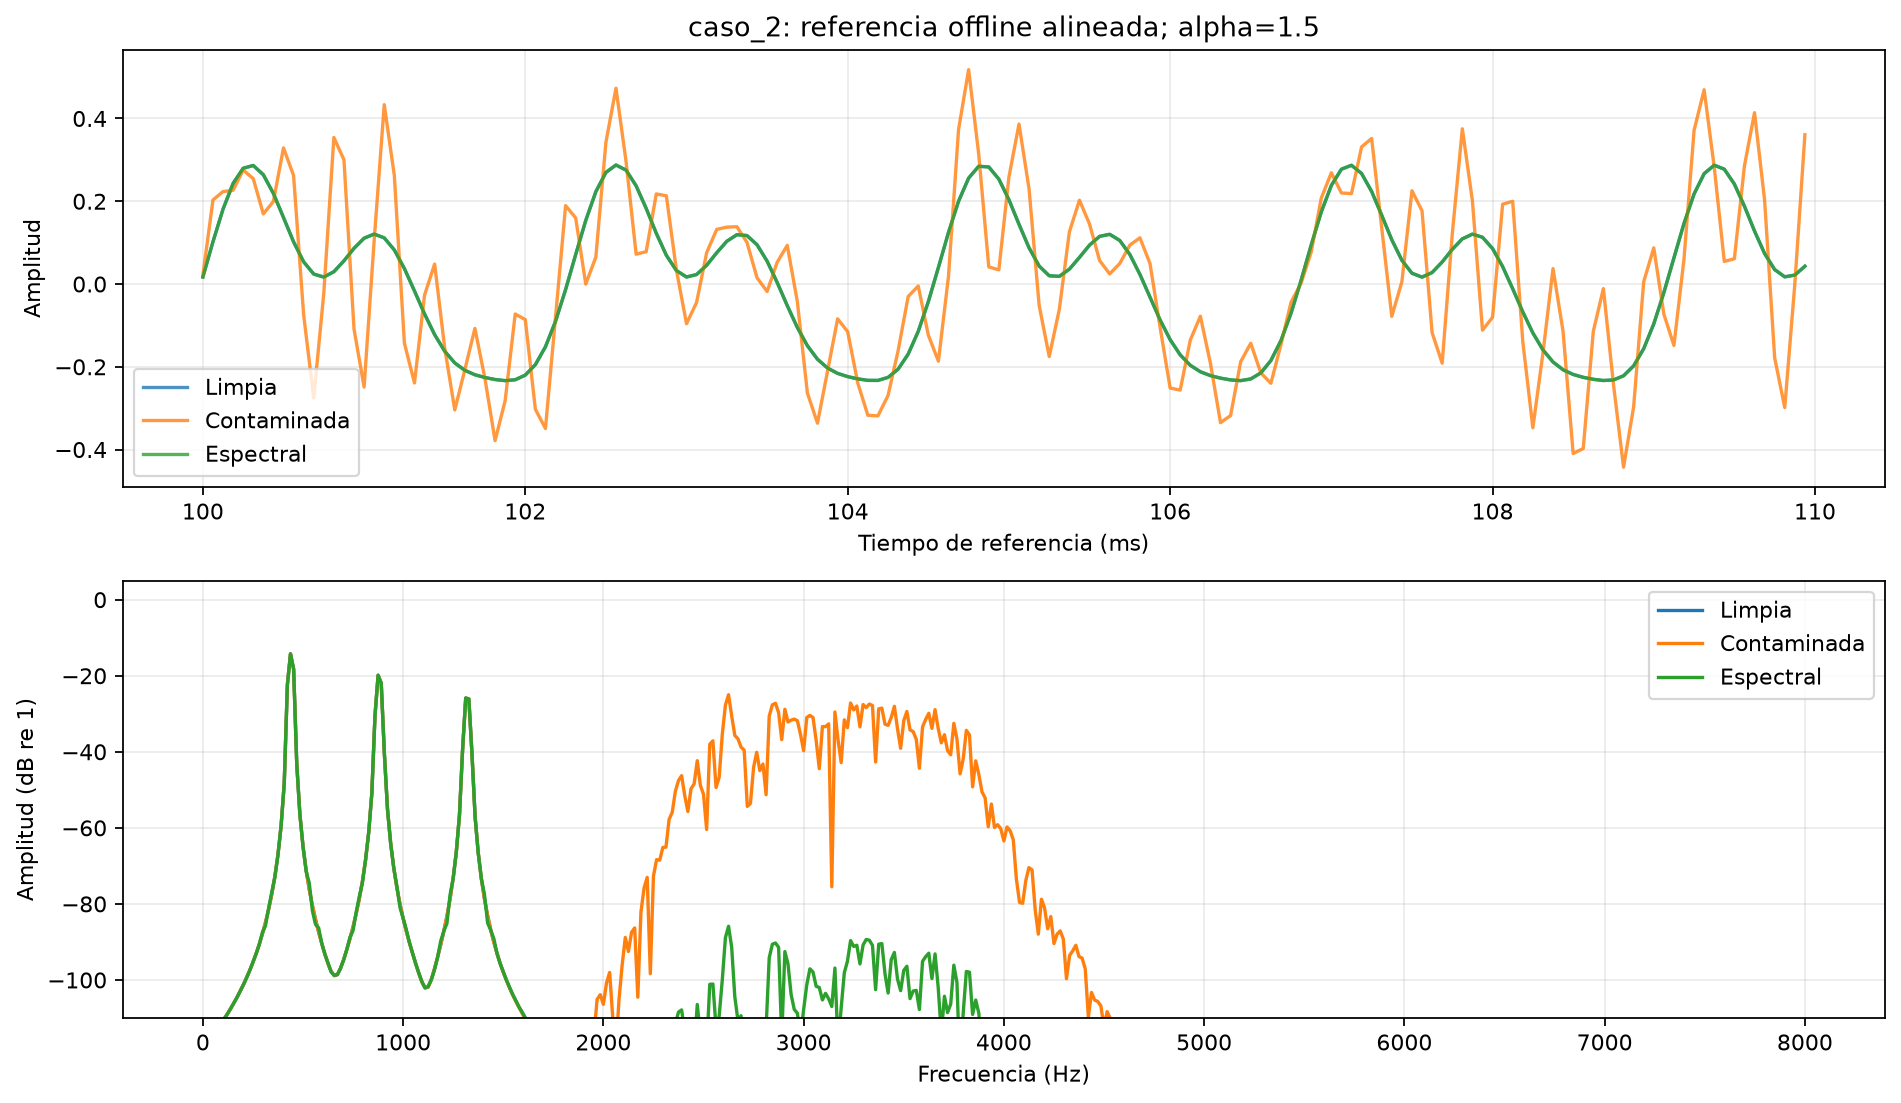

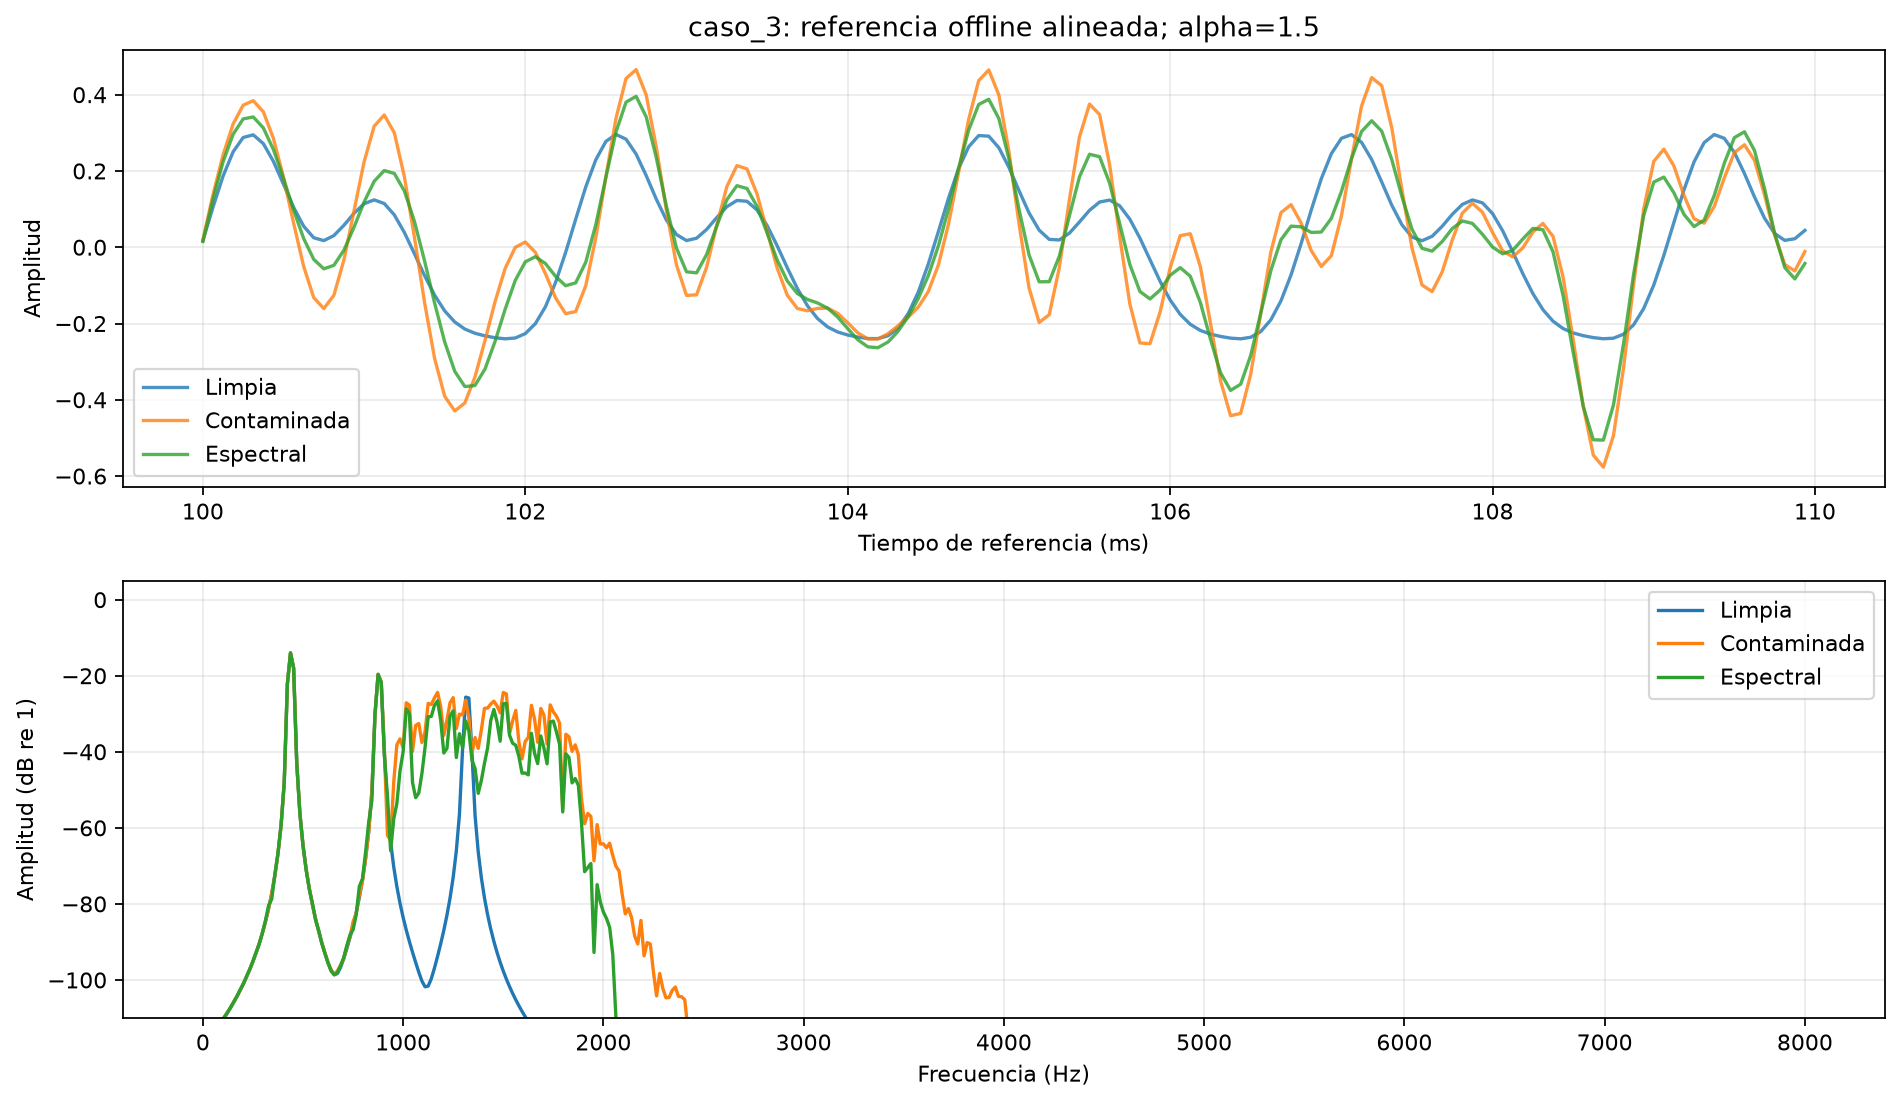

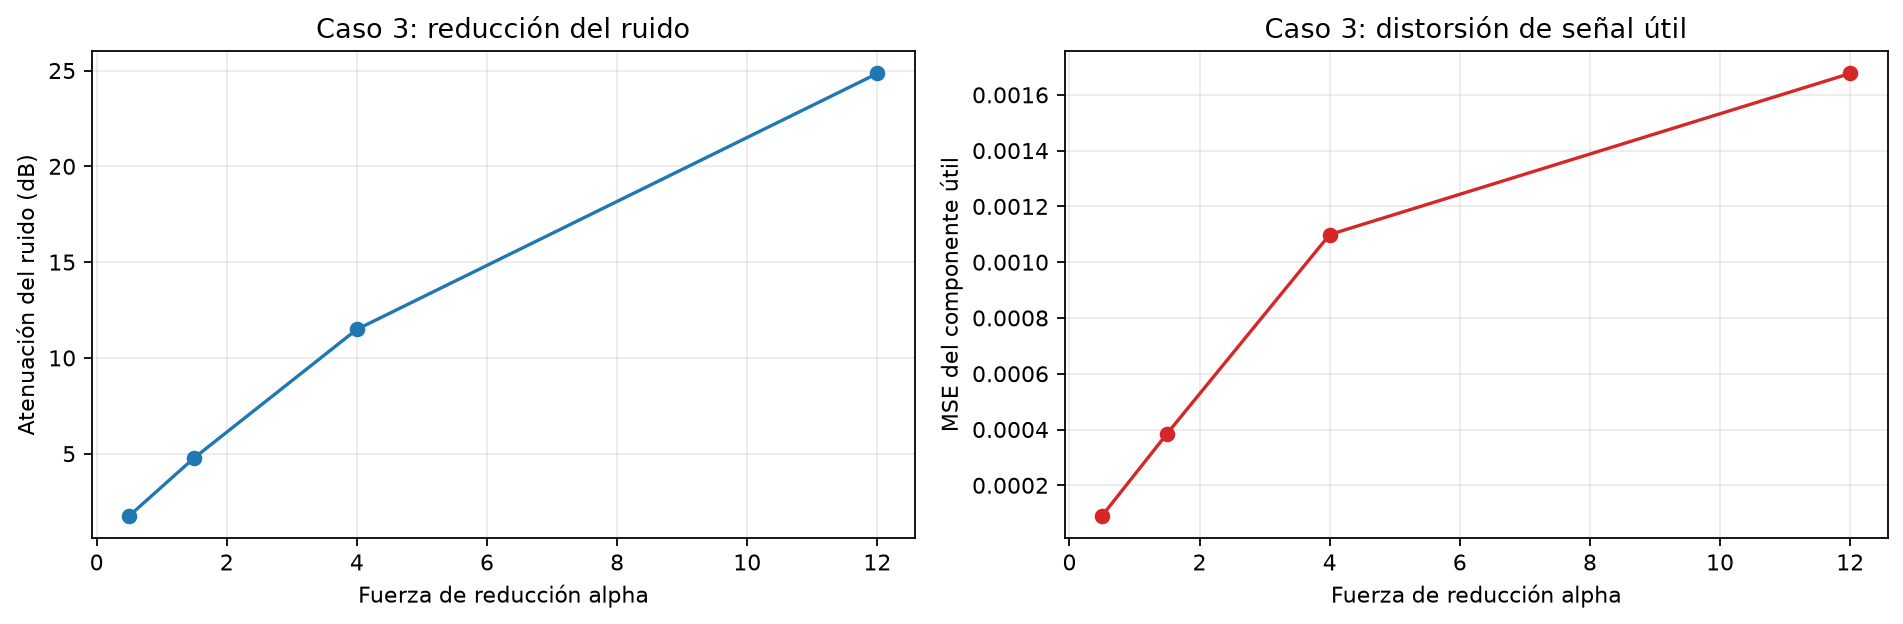

In [8]:
from src.filtrado_espectral import ejecutar_espectral

espectral = ejecutar_espectral(casos)

print("Resultados espectrales:")
for fila in espectral["metricas"]:
    print(
        f"{fila['caso']}: "
        f"mejora SNR = {fila['mejora_snr_db']:.3f} dB; "
        f"energía útil = {fila['energia_util_conservada_pct']:.2f}%"
    )

print("\nExperimento de reducción agresiva:")
for fila in espectral["compromiso"]:
    print(
        f"alpha = {fila['alpha']:g}: "
        f"atenuación ruido = {fila['atenuacion_ruido_total_db']:.2f} dB; "
        f"distorsión útil MSE = "
        f"{fila['distorsion_componente_util_mse']:.6g}"
    )

for nombre in [
    "caso_1_espectral.png",
    "caso_2_espectral.png",
    "caso_3_espectral.png",
    "espectral_compromiso.png",
]:
    display(Image(filename=str(raiz / "resultados" / "figuras" / nombre)))

## 7. Comparación automática sobre un intervalo común

Se comparan entrada sin filtrar, FIR y método espectral utilizando las
mismas muestras de referencia. Se excluyen los bordes y se compensa únicamente
el retardo de grupo conocido del FIR. No se ajustan amplitudes ni fases.

Las métricas principales son:

$$MSE=\frac{1}{L_v}\sum_n(s[n]-\widehat{s}[n])^2,$$

$$SNR=10\log_{10}
\frac{\sum_n s[n]^2}{\sum_n(s[n]-\widehat{s}[n])^2},$$

$$\Delta SNR=SNR_{\mathrm{salida}}-SNR_{\mathrm{entrada}}.$$

También se reportan energía útil conservada, distorsión útil, atenuación
del ruido y de su componente dominante, tiempo amortizado de procesamiento
y memoria base estimada.

Para evaluar los componentes del método espectral se reutilizan las
máscaras aprendidas desde la mezcla. No se aprende desde las referencias.

La SNR objetivo de 2 dB corresponde al registro completo. Al recortar el
intervalo puede cambiar ligeramente; la mejora siempre se calcula contra
la entrada del mismo intervalo.

Los tiempos corresponden a Python y se regeneran en cada computadora.
El FIR usa un bucle de Python y la FFT una biblioteca optimizada:
estos tiempos no predicen directamente el desempeño del firmware.
La memoria es una estimación de diseño, no una medición del hardware.

Los objetivos de calidad de `metadatos/comparacion.json` son propuestas
para este banco de pruebas, no umbrales impuestos por el profesor.

Fuente de las ecuaciones: Tarea 1, apartado 2.5.

caso_1 / sin_filtrar: MSE=4.907e-02; mejora=0.000 dB; referencia
caso_1 / FIR: MSE=5.029e-09; mejora=69.894 dB; cumple
caso_1 / espectral: MSE=5.709e-08; mejora=59.343 dB; cumple
caso_2 / sin_filtrar: MSE=1.702e-02; mejora=0.000 dB; referencia
caso_2 / FIR: MSE=8.134e-10; mejora=73.208 dB; cumple
caso_2 / espectral: MSE=7.214e-09; mejora=63.729 dB; cumple
caso_3 / sin_filtrar: MSE=1.803e-02; mejora=0.000 dB; referencia
caso_3 / FIR: MSE=1.723e-02; mejora=0.196 dB; no_cumple
caso_3 / espectral: MSE=6.400e-03; mejora=4.498 dB; cumple


# Comparación automática

Mismo intervalo de referencia para entrada, FIR y espectral.

| Caso | Método | MSE | SNR salida (dB) | Mejora (dB) | Energía útil (%) | Criterio |
|---|---|---:|---:|---:|---:|---|
| caso_1 | sin_filtrar | 0.0490732 | 2.018 | 0.000 | 100.000 | referencia |
| caso_1 | FIR | 5.02878e-09 | 71.912 | 69.894 | 99.994 | cumple |
| caso_1 | espectral | 5.70857e-08 | 61.361 | 59.343 | 99.999 | cumple |
| caso_2 | sin_filtrar | 0.017025 | 2.013 | 0.000 | 100.000 | referencia |
| caso_2 | FIR | 8.13402e-10 | 75.220 | 73.208 | 99.994 | cumple |
| caso_2 | espectral | 7.21391e-09 | 65.742 | 63.729 | 100.000 | cumple |
| caso_3 | sin_filtrar | 0.0180299 | 2.010 | 0.000 | 100.000 | referencia |
| caso_3 | FIR | 0.0172328 | 2.207 | 0.196 | 99.994 | no_cumple |
| caso_3 | espectral | 0.00640009 | 6.508 | 4.498 | 96.420 | cumple |

## Interpretación y límites

En los casos separados, compare MSE y SNR para determinar qué salida se aproxima más a la referencia. En superposición, compare además distorsión y energía útil: reducir ruido puede eliminar componentes útiles.
La energía de salida total no equivale a energía útil conservada. Las componentes de evaluación del método espectral usan las máscaras aprendidas desde la mezcla.
FIR se compensa 40 muestras en este diseño. La salida espectral es una referencia offline alineada. Esta comparación de calidad no elimina ni mide las latencias físicas.
Los tiempos se miden de nuevo en cada máquina y ejecución. La RAM estimada no es una medición del consumo de Python ni del firmware.
Para el artículo se deben explicar resultados y fallos, no copiar solo esta tabla. La propuesta de placa y comunicación sigue pendiente.



Tiempos amortizados medidos en esta computadora:
caso_1 / FIR: 1.6404 ms por bloque/marco
caso_1 / espectral: 0.0963 ms por bloque/marco
caso_2 / FIR: 1.5805 ms por bloque/marco
caso_2 / espectral: 0.0982 ms por bloque/marco
caso_3 / FIR: 1.6178 ms por bloque/marco
caso_3 / espectral: 0.0979 ms por bloque/marco


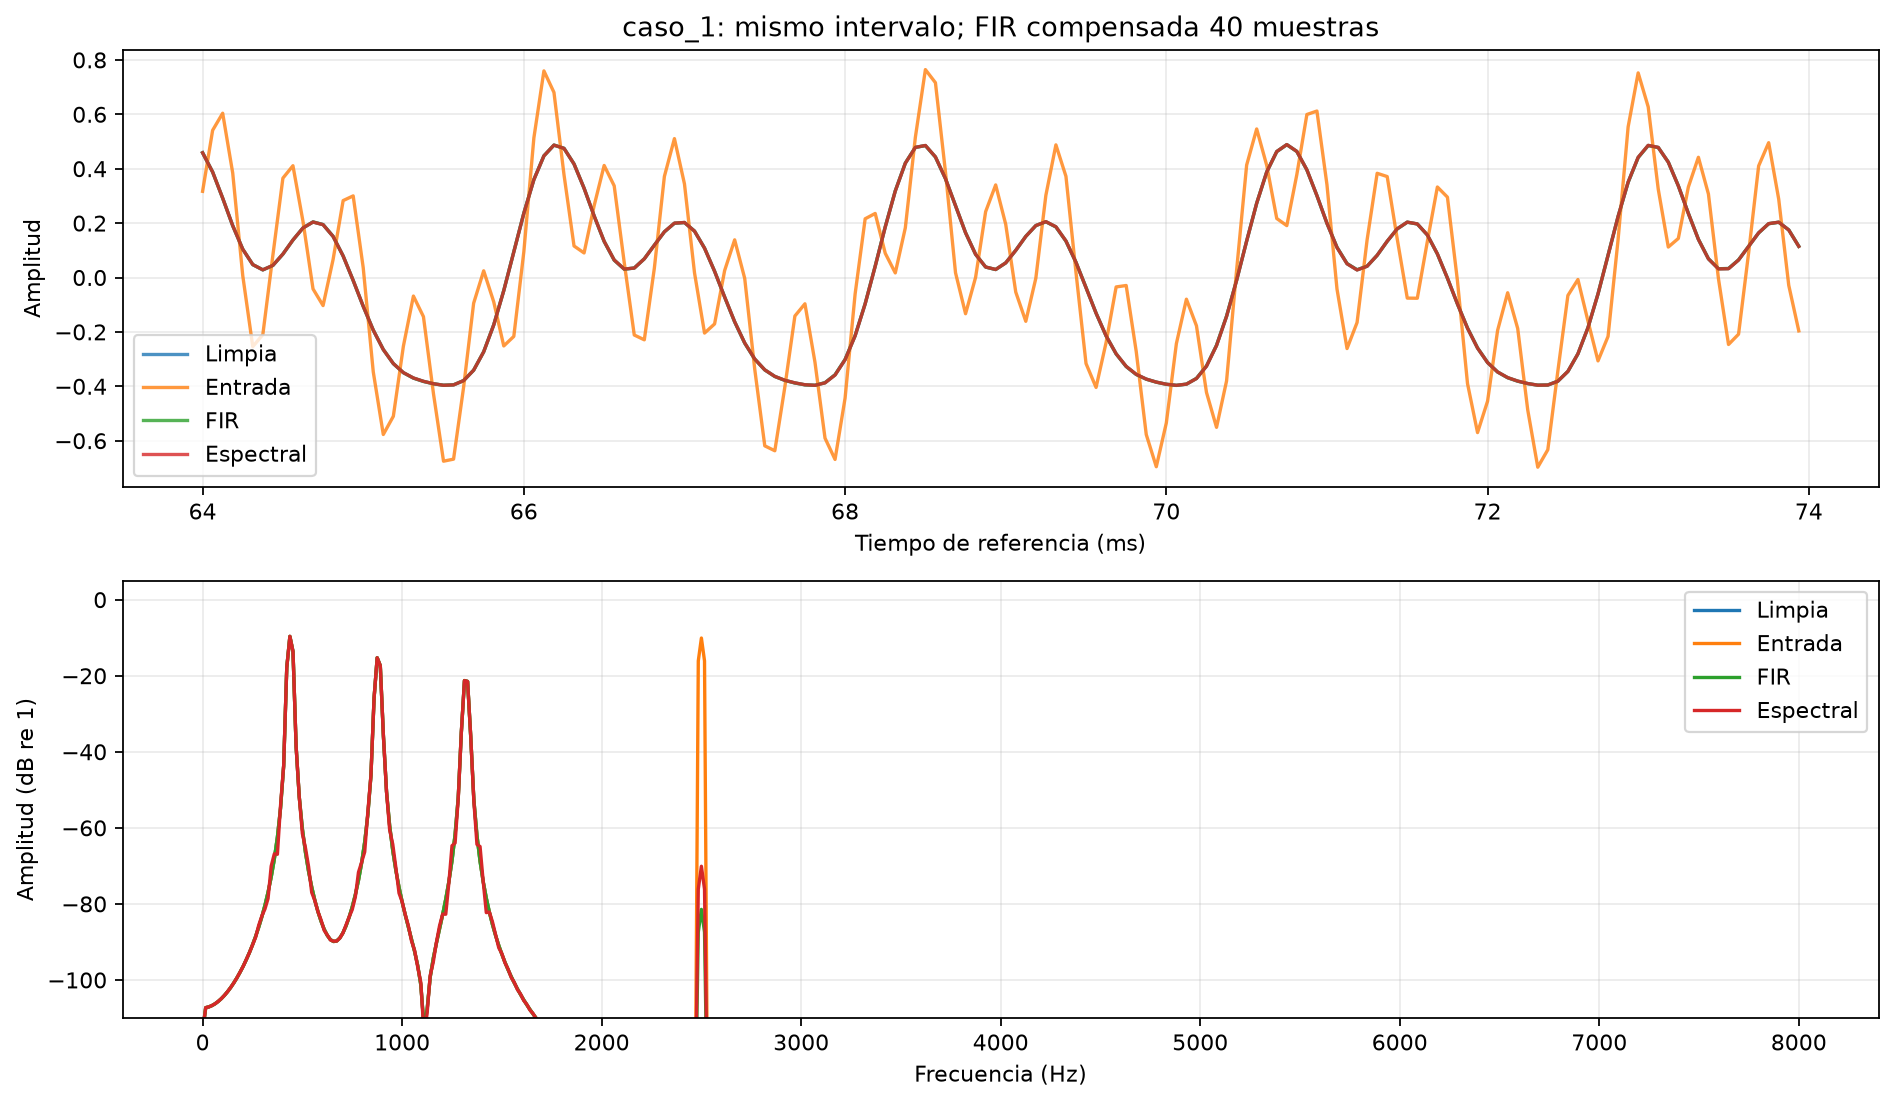

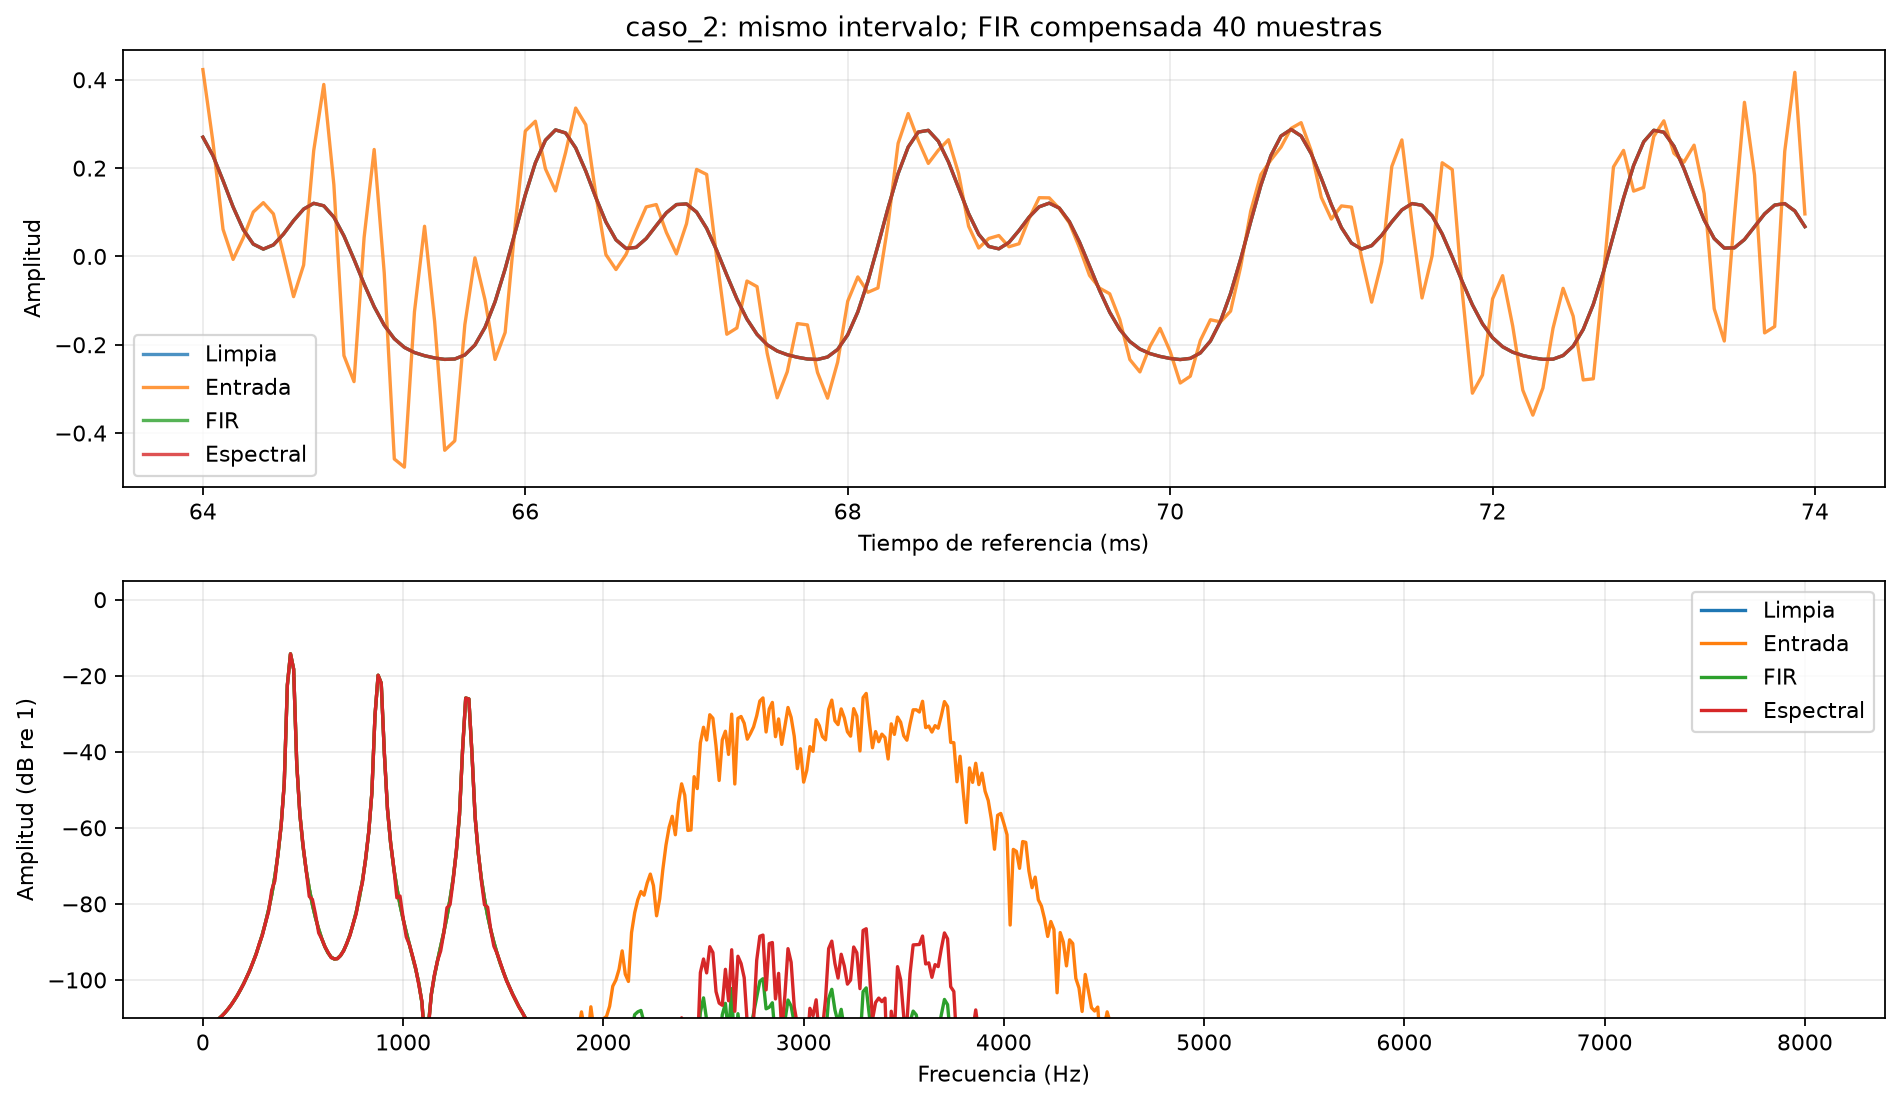

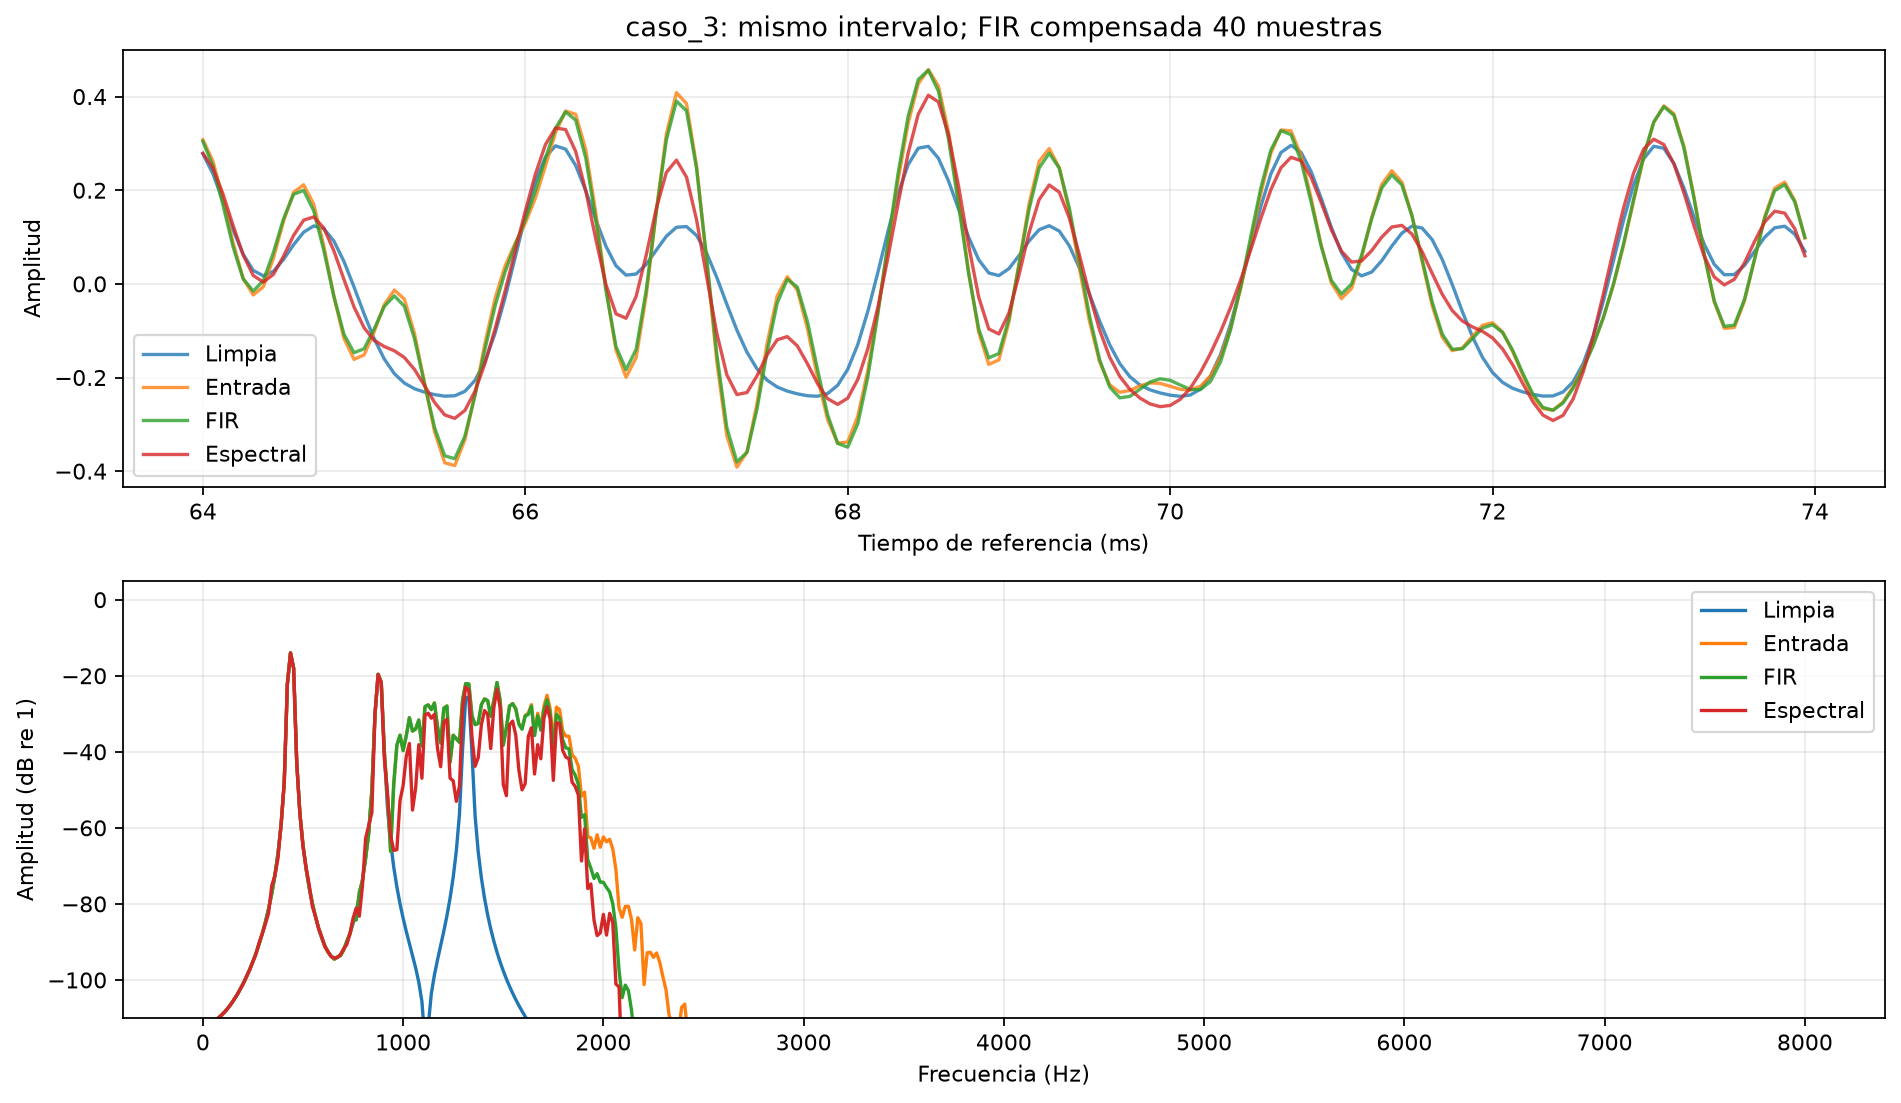

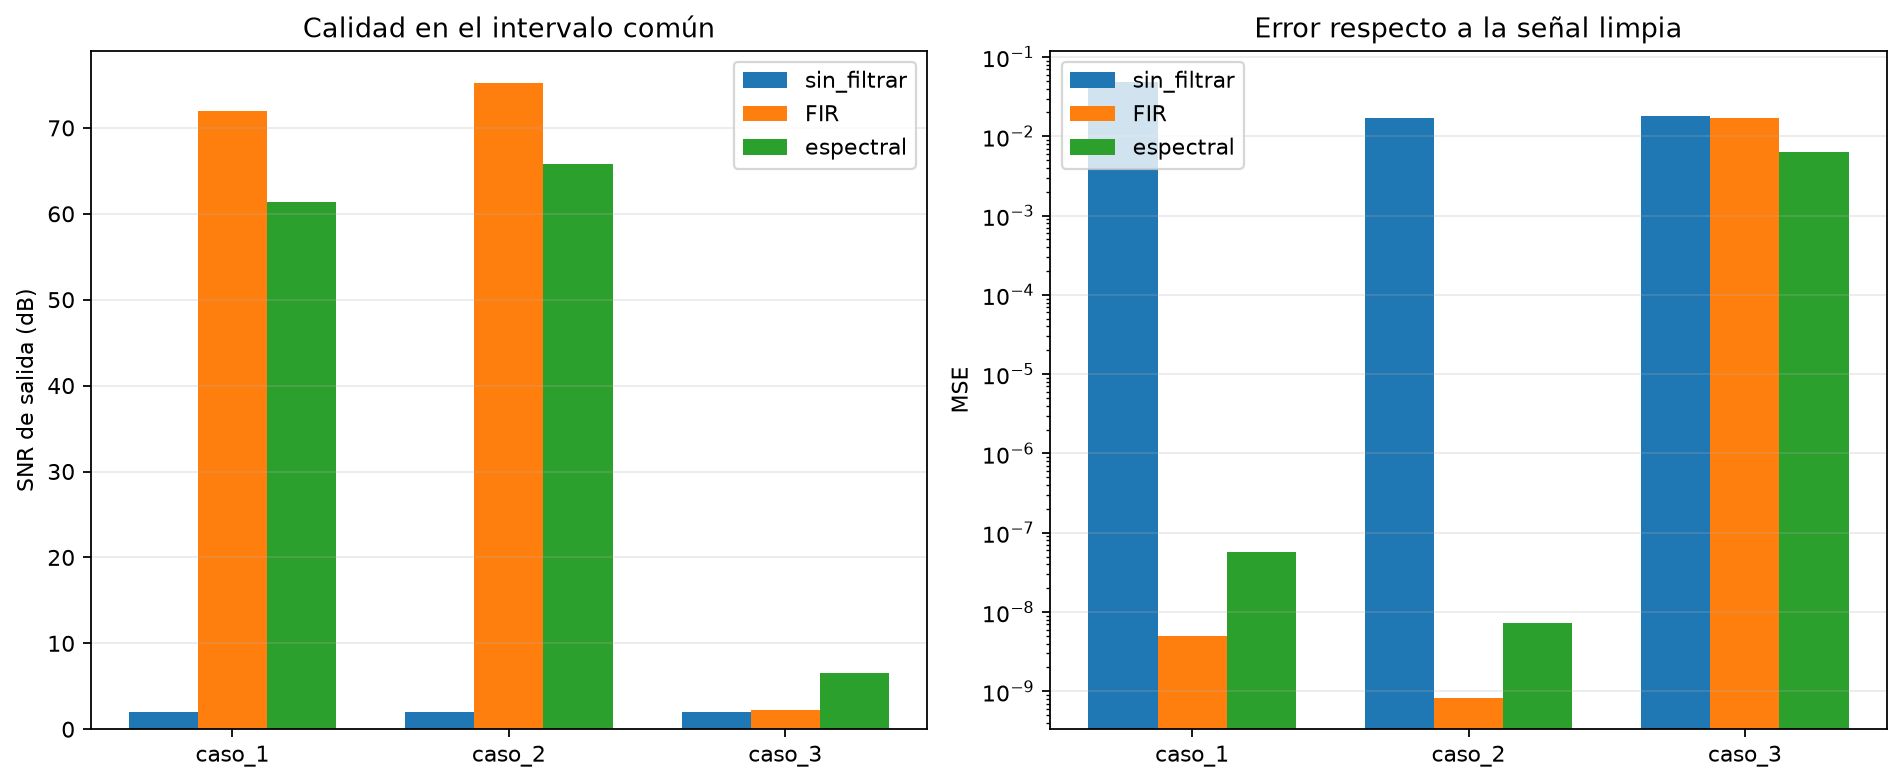

In [9]:
from src.comparacion import ejecutar_comparacion
from IPython.display import Markdown

comparacion = ejecutar_comparacion(casos)

resumen = raiz / "resultados" / "comparacion_resumen.md"
display(Markdown(resumen.read_text(encoding="utf-8")))

print("\nTiempos amortizados medidos en esta computadora:")
for fila in comparacion["tiempos"]:
    print(
        f"{fila['caso']} / {fila['metodo']}: "
        f"{fila['tiempo_medio_bloque_mediana_ms']:.4f} ms por bloque/marco"
    )

for nombre in [
    "caso_1_comparacion.png",
    "caso_2_comparacion.png",
    "caso_3_comparacion.png",
    "comparacion_metricas.png",
]:
    display(Image(filename=str(raiz / "resultados" / "figuras" / nombre)))